# Khám phá PTB-XL waveform và bài toán đa nhãn

Notebook để **đọc đặc tính dữ liệu**, không train mô hình. Chỉ upload file `.ipynb` này vào Kaggle và Add Input `khyeh0719/ptb-xl-dataset`. Mặc định dùng `/kaggle/input/datasets/khyeh0719/ptb-xl-dataset` và tự tìm thư mục con chứa CSV.

**Chạy CPU là đủ; không cần bật hai GPU.** Internet chỉ cần để cài thư viện nếu môi trường chưa có. Mã hỗ trợ đã nhúng trong notebook.

Phân tích metadata và nhãn trên **toàn bộ bản ghi**. Phần đọc tín hiệu mặc định khảo sát **256 bản ghi**, lấy mẫu có seed và phủ các split, để giảm I/O. Có thể đặt `WAVEFORM_SAMPLE_SIZE=None` để đọc toàn bộ waveform. Thống kê mẫu waveform không được hiểu là thống kê chính xác toàn bộ dataset.

Pipeline waveform hiện tại là **multi-label classification**: đầu vào `(12, số mẫu thời gian)`, đầu ra vector 0/1 dài 5, 23 hoặc 71. Một ECG có thể có nhiều nhãn; không phải softmax chọn đúng một bệnh. Notebook đối chiếu theo cách tạo nhãn của code đang dùng: mọi SCP key được giữ bất kể likelihood, min-count 10, giữ cả bản ghi không có nhãn thuộc tác vụ.

## 1. Cấu hình và thư viện

In [1]:
from pathlib import Path
import os, sys, json, subprocess, hashlib, base64, zipfile

DATA_ROOT = Path('/kaggle/input/datasets/khyeh0719/ptb-xl-dataset')
OUTPUT = Path('/kaggle/working/ptbxl_waveform_eda')
INSTALL_DEPENDENCIES = True
WAVEFORM_SAMPLE_SIZE = 256     # None: quét toàn bộ waveform; metadata luôn dùng toàn bộ
SIGNAL_VERSION = 'hr'          # hr: filename_hr/500 Hz; lr: filename_lr/100 Hz nếu có
SEED = 42
TOP_LABELS = 25
MIN_LABEL_COUNT = 10
TASK_TO_INSPECT = 'ptbxl_super'
EXAMPLE_ECG_IDS = []           # ví dụ [1, 2, 3]; để trống sẽ tự chọn từ mẫu đọc thành công
SCAN_WORKERS = 4
OUTPUT.mkdir(parents=True, exist_ok=True)

if INSTALL_DEPENDENCIES:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pandas>=2.2.3,<3',
                    'wfdb==4.3.0', 'matplotlib>=3.8,<4', 'scipy>=1.11,<2', 'tqdm>=4.66,<5'], check=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, FileLink
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2})
assert SIGNAL_VERSION in ['hr', 'lr'] and SCAN_WORKERS > 0
assert DATA_ROOT.is_dir(), f'Không thấy {DATA_ROOT}; hãy Add Input dataset.'

## 2. Đọc metadata và mã hỗ trợ đi kèm

In [2]:
HELPER_SHA256 = '2fefc318157a8fc0bff37b548dec84a7e751b8d55cd48fd2c652b8cb100ed0e9'
helper = base64.b64decode('IiIiQ1BVLW9ubHkgUFRCLVhMIGV4cGxvcmF0aW9uOiBtZXRhZGF0YSwgYmVuY2htYXJrLWNvbXBhdGlibGUgbGFiZWxzIGFuZCBXRkRCLiIiIgppbXBvcnQgYXN0CmZyb20gY29sbGVjdGlvbnMgaW1wb3J0IENvdW50ZXIKZnJvbSBwYXRobGliIGltcG9ydCBQYXRoCgppbXBvcnQgbnVtcHkgYXMgbnAKaW1wb3J0IHBhbmRhcyBhcyBwZAoKTEVBRFMgPSBbJ2knLCAnaWknLCAnaWlpJywgJ2F2cicsICdhdmwnLCAnYXZmJywgJ3YxJywgJ3YyJywgJ3YzJywgJ3Y0JywgJ3Y1JywgJ3Y2J10KVEFTS1MgPSB7J3B0YnhsX3N1cGVyJzogKCdkaWFnbm9zdGljX2NsYXNzJywgNSksCiAgICAgICAgICdwdGJ4bF9zdWInOiAoJ2RpYWdub3N0aWNfc3ViY2xhc3MnLCAyMyksICdwdGJ4bF9hbGwnOiAoTm9uZSwgNzEpfQoKCmRlZiBsb2FkX21ldGFkYXRhKGRhdGFfcm9vdCk6CiAgICByb290ID0gUGF0aChkYXRhX3Jvb3QpCiAgICBmaWxlcyA9IFtyb290IC8gJ3B0YnhsX2RhdGFiYXNlLmNzdiddIGlmIChyb290IC8gJ3B0YnhsX2RhdGFiYXNlLmNzdicpLmlzX2ZpbGUoKSBlbHNlIHNvcnRlZChyb290LnJnbG9iKCdwdGJ4bF9kYXRhYmFzZS5jc3YnKSkKICAgIGlmIGxlbihmaWxlcykgIT0gMToKICAgICAgICByYWlzZSBWYWx1ZUVycm9yKGYnRXhwZWN0ZWQgb25lIHB0YnhsX2RhdGFiYXNlLmNzdiB1bmRlciB7cm9vdH07IGZvdW5kIHtmaWxlc30nKQogICAgcm9vdCA9IGZpbGVzWzBdLnBhcmVudAogICAgZnJhbWUgPSBwZC5yZWFkX2NzdihmaWxlc1swXSkuc29ydF92YWx1ZXMoJ2VjZ19pZCcpLnJlc2V0X2luZGV4KGRyb3A9VHJ1ZSkKICAgIHJlcXVpcmVkID0geydlY2dfaWQnLCAncGF0aWVudF9pZCcsICdzdHJhdF9mb2xkJywgJ3NjcF9jb2Rlcyd9CiAgICBpZiBub3QgcmVxdWlyZWQuaXNzdWJzZXQoZnJhbWUuY29sdW1ucyk6CiAgICAgICAgcmFpc2UgVmFsdWVFcnJvcihmJ01pc3NpbmcgbWV0YWRhdGEgY29sdW1uczoge3JlcXVpcmVkIC0gc2V0KGZyYW1lLmNvbHVtbnMpfScpCiAgICBwYXJzZWQgPSBbXQogICAgZm9yIGVjZ19pZCwgdmFsdWUgaW4gemlwKGZyYW1lLmVjZ19pZCwgZnJhbWUuc2NwX2NvZGVzKToKICAgICAgICB0cnk6CiAgICAgICAgICAgIHJlc3VsdCA9IGFzdC5saXRlcmFsX2V2YWwoc3RyKHZhbHVlKS5yZXBsYWNlKCduYW4nLCAnTm9uZScpKQogICAgICAgICAgICBpZiBub3QgaXNpbnN0YW5jZShyZXN1bHQsIGRpY3QpOgogICAgICAgICAgICAgICAgcmFpc2UgVmFsdWVFcnJvcignRXhwZWN0ZWQgYSBkaWN0JykKICAgICAgICBleGNlcHQgKFZhbHVlRXJyb3IsIFN5bnRheEVycm9yKSBhcyBlcnJvcjoKICAgICAgICAgICAgcmFpc2UgVmFsdWVFcnJvcihmJ0ludmFsaWQgc2NwX2NvZGVzIGZvciBlY2dfaWQ9e2VjZ19pZH06IHt2YWx1ZSFyfScpIGZyb20gZXJyb3IKICAgICAgICBwYXJzZWQuYXBwZW5kKHJlc3VsdCkKICAgIGZyYW1lWydzY3BfY29kZXMnXSA9IHBhcnNlZAogICAgZnJhbWVbJ3NwbGl0J10gPSBucC5zZWxlY3QoW2ZyYW1lLnN0cmF0X2ZvbGQuYmV0d2VlbigxLCA4KSwgZnJhbWUuc3RyYXRfZm9sZC5lcSg5KSwgZnJhbWUuc3RyYXRfZm9sZC5lcSgxMCldLAogICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgWyd0cmFpbicsICd2YWxpZGF0aW9uJywgJ3Rlc3QnXSwgZGVmYXVsdD0naW52YWxpZF9mb2xkJykKICAgIHN0YXRlbWVudHMgPSBwZC5yZWFkX2Nzdihyb290IC8gJ3NjcF9zdGF0ZW1lbnRzLmNzdicsIGluZGV4X2NvbD0wKQogICAgcmV0dXJuIHJvb3QsIGZyYW1lLCBzdGF0ZW1lbnRzCgoKZGVmIG1ldGFkYXRhX2F1ZGl0KGZyYW1lKToKICAgIHJldHVybiBwZC5EYXRhRnJhbWUoewogICAgICAgICdkdHlwZSc6IGZyYW1lLmR0eXBlcy5hc3R5cGUoc3RyKSwKICAgICAgICAnbWlzc2luZyc6IGZyYW1lLmlzbmEoKS5zdW0oKSwKICAgICAgICAnbWlzc2luZ19wZXJjZW50JzogMTAwICogZnJhbWUuaXNuYSgpLm1lYW4oKSwKICAgICAgICAndW5pcXVlX25vbl9udWxsJzogW2ZyYW1lW2NdLmFzdHlwZShzdHIpLm51bmlxdWUoKSBpZiBjID09ICdzY3BfY29kZXMnCiAgICAgICAgICAgICAgICAgICAgICAgICAgICBlbHNlIGZyYW1lW2NdLm51bmlxdWUoZHJvcG5hPVRydWUpIGZvciBjIGluIGZyYW1lLmNvbHVtbnNdLAogICAgfSkuc29ydF92YWx1ZXMoJ21pc3NpbmdfcGVyY2VudCcsIGFzY2VuZGluZz1GYWxzZSkKCgpkZWYgc3BsaXRfYXVkaXQoZnJhbWUpOgogICAgc3VtbWFyeSA9IGZyYW1lLmdyb3VwYnkoJ3NwbGl0JykuYWdnKHJlY29yZHM9KCdlY2dfaWQnLCAnc2l6ZScpLCBwYXRpZW50cz0oJ3BhdGllbnRfaWQnLCAnbnVuaXF1ZScpKQogICAgc3VtbWFyeVsncmVjb3JkX3BlcmNlbnQnXSA9IHN1bW1hcnkucmVjb3JkcyAvIGxlbihmcmFtZSkgKiAxMDAKICAgIHBhdGllbnRfc2V0cyA9IHtzOiBzZXQoZy5wYXRpZW50X2lkLmRyb3BuYSgpKSBmb3IgcywgZyBpbiBmcmFtZS5ncm91cGJ5KCdzcGxpdCcpfQogICAgb3ZlcmxhcHMgPSBbXQogICAgZm9yIGEsIGIgaW4gWygndHJhaW4nLCAndmFsaWRhdGlvbicpLCAoJ3RyYWluJywgJ3Rlc3QnKSwgKCd2YWxpZGF0aW9uJywgJ3Rlc3QnKV06CiAgICAgICAgY29tbW9uID0gcGF0aWVudF9zZXRzLmdldChhLCBzZXQoKSkgJiBwYXRpZW50X3NldHMuZ2V0KGIsIHNldCgpKQogICAgICAgIG92ZXJsYXBzLmFwcGVuZChkaWN0KHNwbGl0X2E9YSwgc3BsaXRfYj1iLCBvdmVybGFwcGluZ19wYXRpZW50cz1sZW4oY29tbW9uKSwgZXhhbXBsZXM9c3RyKHNvcnRlZChjb21tb24pWzoxMF0pKSkKICAgIHJldHVybiBzdW1tYXJ5LCBwZC5EYXRhRnJhbWUob3ZlcmxhcHMpCgoKZGVmIGxpa2VsaWhvb2RfdGFibGUoZnJhbWUsIHN0YXRlbWVudHMpOgogICAgZW50cmllcyA9IFsoY29kZSwgbGlrZWxpaG9vZCkgZm9yIGNvZGVzIGluIGZyYW1lLnNjcF9jb2RlcyBmb3IgY29kZSwgbGlrZWxpaG9vZCBpbiBjb2Rlcy5pdGVtcygpXQogICAgdGFibGUgPSBwZC5EYXRhRnJhbWUoZW50cmllcywgY29sdW1ucz1bJ3NjcF9jb2RlJywgJ2xpa2VsaWhvb2QnXSkKICAgIGlmIHRhYmxlLmVtcHR5OgogICAgICAgIHJldHVybiBwZC5EYXRhRnJhbWUoY29sdW1ucz1bJ3NjcF9jb2RlJywgJ29jY3VycmVuY2VzJywgJ3plcm9fbGlrZWxpaG9vZCcsICd1bmtub3duX3N0YXRlbWVudCddKQogICAgdGFibGVbJ2xpa2VsaWhvb2RfbnVtZXJpYyddID0gcGQudG9fbnVtZXJpYyh0YWJsZS5saWtlbGlob29kLCBlcnJvcnM9J2NvZXJjZScpCiAgICByZXN1bHQgPSB0YWJsZS5ncm91cGJ5KCdzY3BfY29kZScpLmFnZyhvY2N1cnJlbmNlcz0oJ3NjcF9jb2RlJywgJ3NpemUnKSwKICAgICAgICB6ZXJvX2xpa2VsaWhvb2Q9KCdsaWtlbGlob29kX251bWVyaWMnLCBsYW1iZGEgeDogaW50KHguZXEoMCkuc3VtKCkpKSwKICAgICAgICBwb3NpdGl2ZV9saWtlbGlob29kPSgnbGlrZWxpaG9vZF9udW1lcmljJywgbGFtYmRhIHg6IGludCh4Lmd0KDApLnN1bSgpKSksCiAgICAgICAgbWlzc2luZ19vcl9ub25fbnVtZXJpYz0oJ2xpa2VsaWhvb2RfbnVtZXJpYycsIGxhbWJkYSB4OiBpbnQoeC5pc25hKCkuc3VtKCkpKSkKICAgIHJlc3VsdFsndW5rbm93bl9zdGF0ZW1lbnQnXSA9IH5yZXN1bHQuaW5kZXguaXNpbihzdGF0ZW1lbnRzLmluZGV4KQogICAgaWYgJ2Rlc2NyaXB0aW9uJyBpbiBzdGF0ZW1lbnRzOgogICAgICAgIHJlc3VsdCA9IHJlc3VsdC5qb2luKHN0YXRlbWVudHNbWydkZXNjcmlwdGlvbiddXSkKICAgIHJldHVybiByZXN1bHQuc29ydF92YWx1ZXMoJ29jY3VycmVuY2VzJywgYXNjZW5kaW5nPUZhbHNlKS5yZXNldF9pbmRleCgpCgoKZGVmIG1ha2VfdGFza190YXJnZXRzKGZyYW1lLCBzdGF0ZW1lbnRzLCB0YXNrLCBtaW5fY291bnQ9MTApOgogICAgIiIiRXhhY3RseSBtYXRjaCB0aGUgY3VycmVudCB3YXZlZm9ybSBub3RlYm9vaydzIGtleS1wcmVzZW5jZSBzZW1hbnRpY3MuCgogICAgTWFwcGluZy1jb3VudHMgY2FuIGNvdW50IHRoZSBzYW1lIHN1cGVyY2xhc3MgdHdpY2UgZm9yIG9uZSByZWNvcmQsIGFzIGluCiAgICB0aGUgdXBzdHJlYW0gcHJlcHJvY2Vzc29yLiBQb3NpdGl2ZS1yZWNvcmQgY291bnRzIGFyZSBhbHdheXMgYmluYXJ5LgogICAgIiIiCiAgICBjb2x1bW4sIGV4cGVjdGVkID0gVEFTS1NbdGFza10KICAgIG1hcHBpbmcgPSBzdGF0ZW1lbnRzLmxvY1tzdGF0ZW1lbnRzLmRpYWdub3N0aWMuZ3QoMCksIGNvbHVtbl0uZHJvcG5hKCkudG9fZGljdCgpIGlmIGNvbHVtbiBlbHNlIE5vbmUKICAgIGxpc3RzID0gW1ttYXBwaW5nW2tdIGZvciBrIGluIGNvZGVzIGlmIGsgaW4gbWFwcGluZ10gaWYgbWFwcGluZyBpcyBub3QgTm9uZSBlbHNlIGxpc3QoY29kZXMpCiAgICAgICAgICAgICBmb3IgY29kZXMgaW4gZnJhbWUuc2NwX2NvZGVzXQogICAgb2NjdXJyZW5jZXMgPSBDb3VudGVyKGxhYmVsIGZvciBsYWJlbHMgaW4gbGlzdHMgZm9yIGxhYmVsIGluIGxhYmVscykKICAgIGNsYXNzZXMgPSBzb3J0ZWQobGFiZWwgZm9yIGxhYmVsLCBjb3VudCBpbiBvY2N1cnJlbmNlcy5pdGVtcygpIGlmIGNvdW50ID49IG1pbl9jb3VudCkKICAgIHN0b2kgPSB7bmFtZTogaSBmb3IgaSwgbmFtZSBpbiBlbnVtZXJhdGUoY2xhc3Nlcyl9CiAgICB0YXJnZXRzID0gbnAuemVyb3MoKGxlbihmcmFtZSksIGxlbihjbGFzc2VzKSksIGR0eXBlPW5wLnVpbnQ4KQogICAgZm9yIHJvdywgbGFiZWxzIGluIGVudW1lcmF0ZShsaXN0cyk6CiAgICAgICAgZm9yIGxhYmVsIGluIGxhYmVsczoKICAgICAgICAgICAgaWYgbGFiZWwgaW4gc3RvaToKICAgICAgICAgICAgICAgIHRhcmdldHNbcm93LCBzdG9pW2xhYmVsXV0gPSAxCiAgICBjb3VudHMgPSBwZC5EYXRhRnJhbWUoaW5kZXg9cGQuSW5kZXgoY2xhc3NlcywgbmFtZT0nbGFiZWwnKSkKICAgIGNvdW50c1snbWFwcGluZ19vY2N1cnJlbmNlcyddID0gW29jY3VycmVuY2VzW2NdIGZvciBjIGluIGNsYXNzZXNdCiAgICBjb3VudHNbJ3Bvc2l0aXZlX3JlY29yZHMnXSA9IHRhcmdldHMuc3VtKDApLmFzdHlwZShpbnQpCiAgICBjb3VudHNbJ3ByZXZhbGVuY2VfcGVyY2VudCddID0gdGFyZ2V0cy5tZWFuKDApICogMTAwCiAgICBmb3Igc3BsaXQgaW4gWyd0cmFpbicsICd2YWxpZGF0aW9uJywgJ3Rlc3QnXToKICAgICAgICBtYXNrID0gZnJhbWUuc3BsaXQuZXEoc3BsaXQpLnRvX251bXB5KCkKICAgICAgICBwb3NpdGl2ZXMgPSB0YXJnZXRzW21hc2tdLnN1bSgwKS5hc3R5cGUoaW50KQogICAgICAgIGNvdW50c1tmJ3tzcGxpdH1fcG9zaXRpdmUnXSA9IHBvc2l0aXZlcwogICAgICAgIGNvdW50c1tmJ3tzcGxpdH1fbmVnYXRpdmUnXSA9IGludChtYXNrLnN1bSgpKSAtIHBvc2l0aXZlcwogICAgICAgIGNvdW50c1tmJ3tzcGxpdH1fcHJldmFsZW5jZV9wZXJjZW50J10gPSBwb3NpdGl2ZXMgLyBtYXNrLnN1bSgpICogMTAwIGlmIG1hc2suYW55KCkgZWxzZSBucC5uYW4KICAgICAgICBjb3VudHNbZid7c3BsaXR9X2F1Y19kZWZpbmVkJ10gPSAocG9zaXRpdmVzID4gMCkgJiAocG9zaXRpdmVzIDwgbWFzay5zdW0oKSkKICAgIGlmIGNvbHVtbiBpcyBOb25lIGFuZCAnZGVzY3JpcHRpb24nIGluIHN0YXRlbWVudHM6CiAgICAgICAgY291bnRzID0gY291bnRzLmpvaW4oc3RhdGVtZW50c1tbJ2Rlc2NyaXB0aW9uJ11dKQogICAgY2FyZGluYWxpdHkgPSB0YXJnZXRzLnN1bSgxKS5hc3R5cGUoaW50KQogICAgc3VtbWFyeSA9IGRpY3QodGFzaz10YXNrLCBleHBlY3RlZF9jbGFzc2VzPWV4cGVjdGVkLCBvYnNlcnZlZF9jbGFzc2VzPWxlbihvY2N1cnJlbmNlcyksCiAgICAgICAgICAgICAgICAgICByZXRhaW5lZF9jbGFzc2VzPWxlbihjbGFzc2VzKSwgbWF0Y2hlc19leHBlY3RlZD1sZW4oY2xhc3NlcykgPT0gZXhwZWN0ZWQsCiAgICAgICAgICAgICAgICAgICByZWNvcmRzPWxlbihmcmFtZSksIG5vX2xhYmVsX3JlY29yZHM9aW50KChjYXJkaW5hbGl0eSA9PSAwKS5zdW0oKSksCiAgICAgICAgICAgICAgICAgICBzaW5nbGVfbGFiZWxfcmVjb3Jkcz1pbnQoKGNhcmRpbmFsaXR5ID09IDEpLnN1bSgpKSwKICAgICAgICAgICAgICAgICAgIG11bHRpX2xhYmVsX3JlY29yZHM9aW50KChjYXJkaW5hbGl0eSA+PSAyKS5zdW0oKSksCiAgICAgICAgICAgICAgICAgICBtZWFuX2xhYmVsc19wZXJfcmVjb3JkPWZsb2F0KGNhcmRpbmFsaXR5Lm1lYW4oKSksCiAgICAgICAgICAgICAgICAgICBsYWJlbF9kZW5zaXR5PWZsb2F0KHRhcmdldHMubWVhbigpKSBpZiB0YXJnZXRzLnNpemUgZWxzZSBOb25lKQogICAgcmV0dXJuIGNsYXNzZXMsIHRhcmdldHMsIGNvdW50cywgc3VtbWFyeQoKCmRlZiBzdHJhdGlmaWVkX3NhbXBsZShmcmFtZSwgY291bnQsIHNlZWQ9NDIpOgogICAgIiIiQmFsYW5jZWQgc3BsaXQgY292ZXJhZ2UsIGZvciBkZXNjcmlwdGl2ZSB3YXZlZm9ybSBzY2FubmluZyBvbmx5LiIiIgogICAgaWYgY291bnQgaXMgTm9uZSBvciBjb3VudCA+PSBsZW4oZnJhbWUpOgogICAgICAgIHJldHVybiBmcmFtZS5jb3B5KCkKICAgIGlmIGNvdW50IDw9IDA6CiAgICAgICAgcmFpc2UgVmFsdWVFcnJvcignU2FtcGxlIHNpemUgbXVzdCBiZSBwb3NpdGl2ZSBvciBOb25lJykKICAgIHJuZyA9IG5wLnJhbmRvbS5kZWZhdWx0X3JuZyhzZWVkKQogICAgZ3JvdXBzID0gW2cuaW5kZXgudG9fbnVtcHkoKS5jb3B5KCkgZm9yIF8sIGcgaW4gZnJhbWUuZ3JvdXBieSgnc3BsaXQnLCBzb3J0PVRydWUpXQogICAgZm9yIGdyb3VwIGluIGdyb3VwczoKICAgICAgICBybmcuc2h1ZmZsZShncm91cCkKICAgIGNob3NlbiA9IFtdCiAgICB3aGlsZSBsZW4oY2hvc2VuKSA8IGNvdW50OgogICAgICAgIGJlZm9yZSA9IGxlbihjaG9zZW4pCiAgICAgICAgZm9yIGdyb3VwX2luZGV4LCBncm91cCBpbiBlbnVtZXJhdGUoZ3JvdXBzKToKICAgICAgICAgICAgaWYgbGVuKGNob3NlbikgPCBjb3VudCBhbmQgbGVuKGdyb3VwKToKICAgICAgICAgICAgICAgIGNob3Nlbi5hcHBlbmQoZ3JvdXBbLTFdKQogICAgICAgICAgICAgICAgZ3JvdXBzW2dyb3VwX2luZGV4XSA9IGdyb3VwWzotMV0KICAgICAgICBpZiBsZW4oY2hvc2VuKSA9PSBiZWZvcmU6CiAgICAgICAgICAgIGJyZWFrCiAgICByZXR1cm4gZnJhbWUubG9jW2Nob3Nlbl0uY29weSgpCgoKZGVmIHJlYWRfd2F2ZWZvcm0ocm9vdCwgcm93LCB2ZXJzaW9uPSdocicpOgogICAgaW1wb3J0IHdmZGIKICAgIGNvbHVtbiA9ICdmaWxlbmFtZV9ocicgaWYgdmVyc2lvbiA9PSAnaHInIGVsc2UgJ2ZpbGVuYW1lX2xyJwogICAgaWYgY29sdW1uIG5vdCBpbiByb3cgb3IgcGQuaXNuYShyb3dbY29sdW1uXSk6CiAgICAgICAgcmFpc2UgVmFsdWVFcnJvcihmJ01pc3Npbmcge2NvbHVtbn0gZm9yIGVjZ19pZD17cm93LmVjZ19pZH0nKQogICAgc2lnbmFsLCBoZWFkZXIgPSB3ZmRiLnJkc2FtcChzdHIoUGF0aChyb290KSAvIHN0cihyb3dbY29sdW1uXSkpKQogICAgbmFtZXMgPSBbc3RyKHYpLmxvd2VyKCkgZm9yIHYgaW4gaGVhZGVyWydzaWdfbmFtZSddXQogICAgaWYgbGVuKG5hbWVzKSA9PSAxMiBhbmQgc2V0KG5hbWVzKSA9PSBzZXQoTEVBRFMpOgogICAgICAgIG9yZGVyID0gW25hbWVzLmluZGV4KHYpIGZvciB2IGluIExFQURTXQogICAgICAgIHNpZ25hbCA9IHNpZ25hbFs6LCBvcmRlcl0KICAgICAgICBoZWFkZXIgPSB7KipoZWFkZXIsICdzaWdfbmFtZSc6IFtuYW1lc1tpXSBmb3IgaSBpbiBvcmRlcl0sCiAgICAgICAgICAgICAgICAgICd1bml0cyc6IFtoZWFkZXJbJ3VuaXRzJ11baV0gZm9yIGkgaW4gb3JkZXJdfQogICAgcmV0dXJuIHNpZ25hbCwgaGVhZGVyCgoKZGVmIHdhdmVmb3JtX3N0YXRpc3RpY3Mocm9vdCwgcm93LCB2ZXJzaW9uPSdocicpOgogICAgc2lnbmFsLCBoZWFkZXIgPSByZWFkX3dhdmVmb3JtKHJvb3QsIHJvdywgdmVyc2lvbikKICAgIGZzID0gZmxvYXQoaGVhZGVyWydmcyddKQogICAgcmVjb3JkID0gZGljdChlY2dfaWQ9aW50KHJvdy5lY2dfaWQpLCBzcGxpdD1yb3dbJ3NwbGl0J10sIGZzPWZzLCBzYW1wbGVzPWxlbihzaWduYWwpLAogICAgICAgICAgICAgICAgICBjaGFubmVscz1zaWduYWwuc2hhcGVbMV0sIGR1cmF0aW9uX3NlY29uZHM9bGVuKHNpZ25hbCkgLyBmcywKICAgICAgICAgICAgICAgICAgbGVhZF9vcmRlcj0nfCcuam9pbihoZWFkZXJbJ3NpZ19uYW1lJ10pLCB1bml0cz0nfCcuam9pbihoZWFkZXJbJ3VuaXRzJ10pLAogICAgICAgICAgICAgICAgICBub25maW5pdGVfc2FtcGxlcz1pbnQoKH5ucC5pc2Zpbml0ZShzaWduYWwpKS5zdW0oKSkpCiAgICByb3dzID0gW10KICAgIGZvciBpLCBsZWFkIGluIGVudW1lcmF0ZShoZWFkZXJbJ3NpZ19uYW1lJ10pOgogICAgICAgIHZhbHVlcyA9IHNpZ25hbFs6LCBpXQogICAgICAgIGZpbml0ZSA9IHZhbHVlc1tucC5pc2Zpbml0ZSh2YWx1ZXMpXQogICAgICAgIHJlY29yZF9zdGF0cyA9IGRpY3QoZWNnX2lkPWludChyb3cuZWNnX2lkKSwgc3BsaXQ9cm93WydzcGxpdCddLCBsZWFkPWxlYWQsCiAgICAgICAgICAgICAgICAgICAgICAgICAgICB1bml0PWhlYWRlclsndW5pdHMnXVtpXSwgbm9uZmluaXRlX2ZyYWN0aW9uPWZsb2F0KCh+bnAuaXNmaW5pdGUodmFsdWVzKSkubWVhbigpKSkKICAgICAgICBpZiBsZW4oZmluaXRlKToKICAgICAgICAgICAgcmVjb3JkX3N0YXRzLnVwZGF0ZShtZWFuPWZsb2F0KGZpbml0ZS5tZWFuKCkpLCBzdGQ9ZmxvYXQoZmluaXRlLnN0ZCgpKSwKICAgICAgICAgICAgICAgIG1pbmltdW09ZmxvYXQoZmluaXRlLm1pbigpKSwgbWF4aW11bT1mbG9hdChmaW5pdGUubWF4KCkpLCBwZWFrX3RvX3BlYWs9ZmxvYXQobnAucHRwKGZpbml0ZSkpLAogICAgICAgICAgICAgICAgcm1zPWZsb2F0KG5wLnNxcnQobnAubWVhbihmaW5pdGUgKiogMikpKSwgbWVkaWFuPWZsb2F0KG5wLm1lZGlhbihmaW5pdGUpKSwKICAgICAgICAgICAgICAgIGFic19wOTk9ZmxvYXQobnAucXVhbnRpbGUobnAuYWJzKGZpbml0ZSksIC45OSkpLAogICAgICAgICAgICAgICAgY29uc3RhbnRfbGVhZD1ib29sKG5wLnB0cChmaW5pdGUpID09IDApLAogICAgICAgICAgICAgICAgZnJhY3Rpb25fYWJzX2d0XzNfNV9tdj1mbG9hdCgobnAuYWJzKGZpbml0ZSkgPiAzLjUpLm1lYW4oKSkgaWYgaGVhZGVyWyd1bml0cyddW2ldID09ICdtVicgZWxzZSBOb25lKQogICAgICAgIGVsc2U6CiAgICAgICAgICAgIHJlY29yZF9zdGF0cy51cGRhdGUoY29uc3RhbnRfbGVhZD1UcnVlKQogICAgICAgIHJvd3MuYXBwZW5kKHJlY29yZF9zdGF0cykKICAgIHJldHVybiByZWNvcmQsIHJvd3MK')
assert hashlib.sha256(helper).hexdigest() == HELPER_SHA256
(OUTPUT / 'ptbxl_eda_utils.py').write_bytes(helper)
sys.path.insert(0, str(OUTPUT))
import ptbxl_eda_utils as eda
root, df, statements = eda.load_metadata(DATA_ROOT)
assert TASK_TO_INSPECT in eda.TASKS
print('Data root:', root)
print('ECG records:', len(df), '| Patients:', df.patient_id.nunique(), '| Metadata columns:', len(df.columns))
print('Unique ECG ids:', df.ecg_id.nunique(), '| Duplicate rows by ecg_id:', int(df.ecg_id.duplicated().sum()))
display(df[[c for c in ['ecg_id', 'patient_id', 'age', 'sex', 'strat_fold', 'split', 'filename_hr', 'filename_lr', 'scp_codes'] if c in df]].head())
display(statements.head())
statements.to_csv(OUTPUT / 'scp_statements.csv')

def save_figure(figure, name):
    figure.tight_layout()
    figure.savefig(OUTPUT / name, dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(figure)

Data root: /kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1
ECG records: 21837 | Patients: 18885 | Metadata columns: 29
Unique ECG ids: 21837 | Duplicate rows by ecg_id: 0


,ecg_id,patient_id,age,sex,strat_fold,split,filename_hr,filename_lr,scp_codes
0,1,15709.0,56.0,1,3,train,records500/00000/00001_hr,records100/00000/00001_lr,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
1,2,13243.0,19.0,0,2,train,records500/00000/00002_hr,records100/00000/00002_lr,"{'NORM': 80.0, 'SBRAD': 0.0}"
2,3,20372.0,37.0,1,5,train,records500/00000/00003_hr,records100/00000/00003_lr,"{'NORM': 100.0, 'SR': 0.0}"
3,4,17014.0,24.0,0,3,train,records500/00000/00004_hr,records100/00000/00004_lr,"{'NORM': 100.0, 'SR': 0.0}"
4,5,17448.0,19.0,1,4,train,records500/00000/00005_hr,records100/00000/00005_lr,"{'NORM': 100.0, 'SR': 0.0}"


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7


## 3. Schema, dữ liệu thiếu và số bản ghi mỗi bệnh nhân

Một patient có thể có nhiều ECG. Đơn vị mẫu của mô hình là **ecg_id**, còn kiểm tra leakage cần theo **patient_id**. Các trường metadata được khảo sát ở đây không tự động trở thành đầu vào của mô hình waveform.

,dtype,missing,missing_percent,unique_non_null
electrodes_problems,object,21807,99.862618,14
infarction_stadium2,object,21734,99.528323,3
pacemaker,object,21544,98.658241,4
burst_noise,object,21224,97.192838,103
baseline_drift,object,20230,92.640931,321
extra_beats,object,19883,91.051884,128
static_noise,object,18575,85.062051,124
infarction_stadium1,object,16211,74.236388,6
height,float64,14854,68.022164,77
weight,float64,12408,56.820992,127


,ecg_records
count,18885.000000
mean,1.156315
std,0.524680
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,10.000000


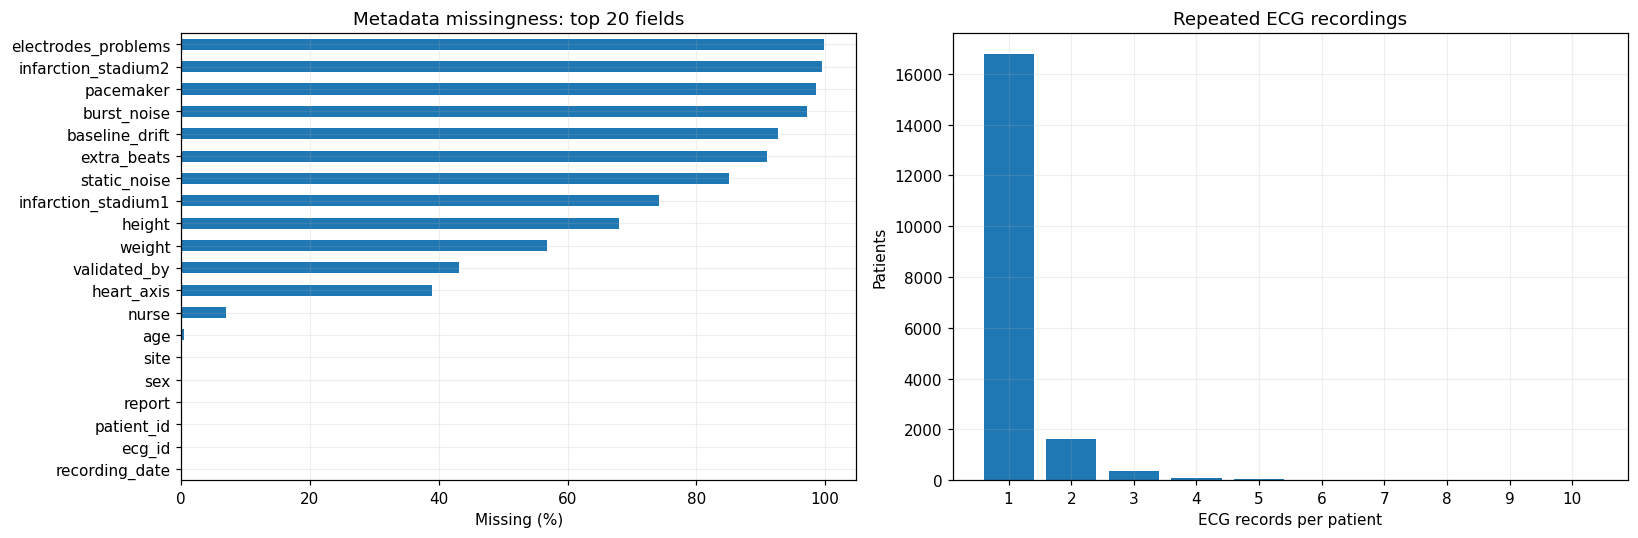

In [3]:
audit = eda.metadata_audit(df)
audit.to_csv(OUTPUT / 'metadata_schema_missing.csv')
display(audit)
patient_counts = df.groupby('patient_id').size().rename('ecg_records')
patient_counts.to_csv(OUTPUT / 'ecg_per_patient.csv')
display(patient_counts.describe().to_frame())
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
audit['missing_percent'].sort_values(ascending=False).head(20).sort_values().plot.barh(ax=axes[0])
axes[0].set(xlabel='Missing (%)', title='Metadata missingness: top 20 fields')
distribution = patient_counts.value_counts().sort_index()
axes[1].bar(distribution.index.astype(str), distribution.values)
axes[1].set(xlabel='ECG records per patient', ylabel='Patients', title='Repeated ECG recordings')
save_figure(fig, 'metadata_missing_and_patient_records.png')

## 4. Tuổi, mã giới tính và các cờ chất lượng có sẵn

Hiển thị tuổi nguyên gốc và báo riêng tuổi ngoài khoảng 0–120 hoặc thiếu; không tự sửa giá trị. Các giá trị này cần đối chiếu tài liệu dataset trước khi xem là lỗi. Trường `sex` được hiển thị theo mã gốc, không tự suy đoán ý nghĩa mã. Các cờ chất lượng là thông tin từ CSV, không phải chẩn đoán từ thuật toán mới.

,age
count,21748.000000
mean,59.836307
std,16.953125
min,2.000000
25%,50.000000
50%,62.000000
75%,72.000000
max,95.000000


,records
sex,
0,11379
1,10458


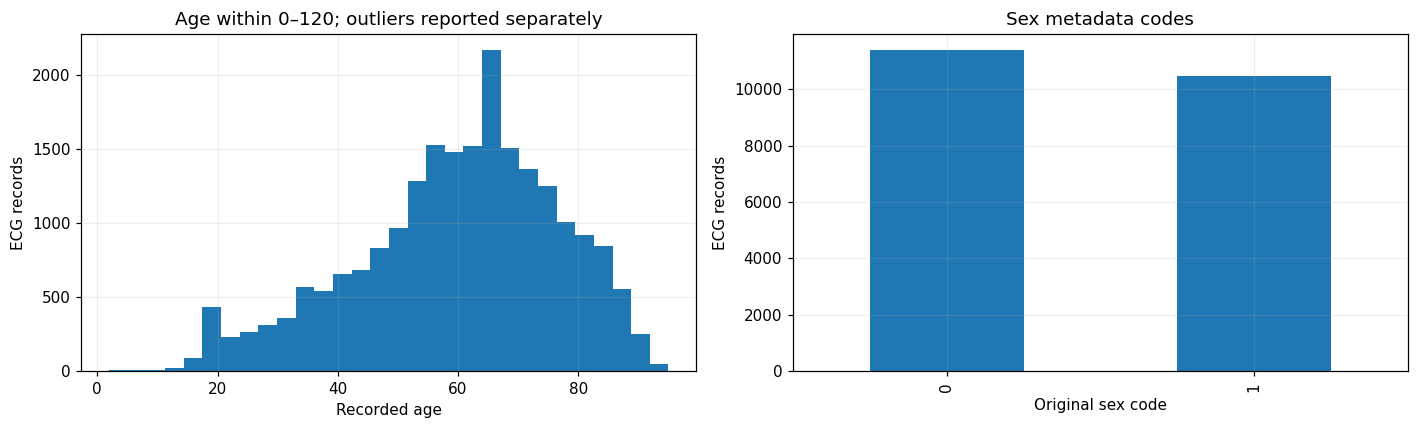

Age audit: {'age_missing': 89, 'age_outside_0_120': 0}


,baseline_drift
baseline_drift,
missing,20230
", V6",222
", V1",95
", II-AVF",60
", V3",59
", V2",58
", V5,V6",57
", alles",55
", I-AVF",47


,static_noise
static_noise,
missing,18575
", I-AVR,",953
", I-AVF,",919
", alles,",524
", I-V1,",156
", I-V2,",144
", I-AVL,",91
", mittel,",70
", leicht,",42


,burst_noise
burst_noise,
missing,21224
alles,140
I-AVF,47
V1,46
"V1,V2",28
I-AVR,24
V2,22
I-V1,21
I-V2,20


,electrodes_problems
electrodes_problems,
missing,21807
V6,8
V4,5
V1,4
V1???,2
V5,2
V3,1
"V5,V6",1
Kontaktprobleme aVL ???,1


,extra_beats
extra_beats,
missing,19883
1ES,409
SVES,381
2ES,179
VES,159
"VES1,alles",151
3ES,81
"VES2,alles",70
"1,alles",61


,pacemaker
pacemaker,
missing,21544
"ja, pacemaker",287
"ja, nan",3
"PACE????, nan",2
"?, nan",1


,validated_by_human
validated_by_human,
True,16094
False,5743


,initial_autogenerated_report
initial_autogenerated_report,
False,15024
True,6813


In [4]:
demographics = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
if 'age' in df:
    age = pd.to_numeric(df.age, errors='coerce')
    demographics['age_missing'] = int(age.isna().sum())
    demographics['age_outside_0_120'] = int((age.notna() & ~age.between(0, 120)).sum())
    display(age.describe().to_frame('age'))
    age[age.between(0, 120)].hist(bins=30, ax=axes[0])
    axes[0].set(xlabel='Recorded age', ylabel='ECG records', title='Age within 0–120; outliers reported separately')
else:
    axes[0].text(.1, .5, 'No age column')
if 'sex' in df:
    sex_counts = df.sex.fillna('missing').astype(str).value_counts()
    display(sex_counts.to_frame('records'))
    sex_counts.plot.bar(ax=axes[1])
    axes[1].set(xlabel='Original sex code', ylabel='ECG records', title='Sex metadata codes')
else:
    axes[1].text(.1, .5, 'No sex column')
save_figure(fig, 'demographics.png')
print('Age audit:', demographics)
quality_columns = [c for c in ['baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems',
                             'extra_beats', 'pacemaker', 'validated_by_human', 'initial_autogenerated_report'] if c in df]
quality_rows = []
for column in quality_columns:
    values = df[column].fillna('missing').astype(str).value_counts()
    display(values.head(15).to_frame(column))
    quality_rows.extend(dict(field=column, value=k, records=int(v)) for k, v in values.items())
pd.DataFrame(quality_rows).to_csv(OUTPUT / 'metadata_quality_flags.csv', index=False)

## 5. Fold, train/validation/test và trùng bệnh nhân
Pipeline hiện tại dùng fold 1–8 train, fold 9 validation, fold 10 test. Nếu có invalid fold, duplicate ecg_id hoặc overlap bệnh nhân, cần giải quyết trước khi train.

,records,patients,record_percent
split,,,
test,2203,1907,10.088382
train,17441,15031,79.869030
validation,2193,1947,10.042588


,split_a,split_b,overlapping_patients,examples
0,train,validation,0,[]
1,train,test,0,[]
2,validation,test,0,[]


,records,patients
strat_fold,,
1,2177,1879
2,2184,1850
3,2194,1889
4,2175,1883
5,2176,1890
6,2178,1886
7,2178,1871
8,2179,1883
9,2193,1947


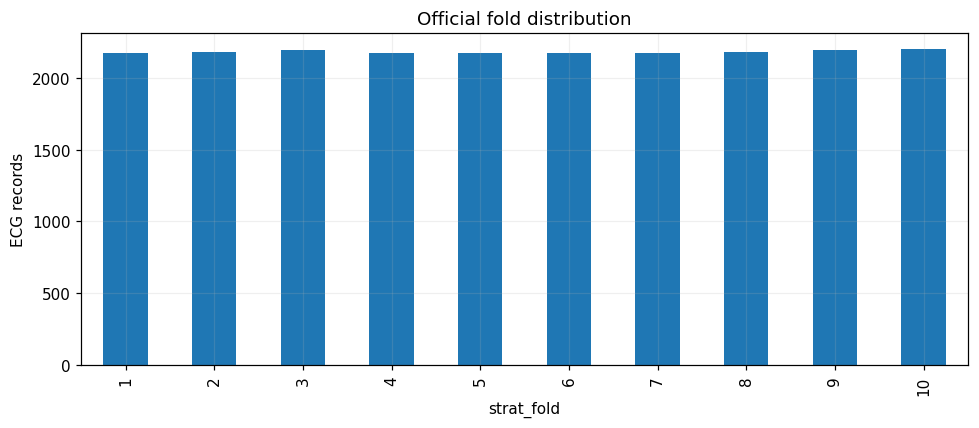

In [5]:
split_summary, overlaps = eda.split_audit(df)
display(split_summary)
display(overlaps)
split_summary.to_csv(OUTPUT / 'split_summary.csv')
overlaps.to_csv(OUTPUT / 'patient_overlap.csv', index=False)
fold_summary = df.groupby('strat_fold').agg(records=('ecg_id', 'size'), patients=('patient_id', 'nunique'))
display(fold_summary)
fold_summary.to_csv(OUTPUT / 'fold_summary.csv')
fig, ax = plt.subplots(figsize=(9, 4))
fold_summary.records.plot.bar(ax=ax)
ax.set(xlabel='strat_fold', ylabel='ECG records', title='Official fold distribution')
save_figure(fig, 'fold_distribution.png')
if df.ecg_id.duplicated().any() or df.split.eq('invalid_fold').any() or overlaps.overlapping_patients.gt(0).any():
    print('DATA AUDIT ALERT: duplicated ECG ids / invalid folds / overlapping patients detected; inspect tables above.')

## 6. `scp_codes`, likelihood và ý nghĩa nhãn

`scp_codes` là dictionary `{mã SCP: likelihood}`. **Pipeline benchmark hiện tại dùng sự hiện diện của key làm nhãn dương, kể cả likelihood=0**, không dùng likelihood làm target liên tục hoặc trọng số loss. Bảng dưới giúp thấy rõ ảnh hưởng của quy tắc này; giá trị 0 ở likelihood không trở thành target âm trong cách triển khai hiện tại.

`ptbxl_all`: lấy các SCP key. `ptbxl_super`/`ptbxl_sub`: chỉ ánh xạ các mã `diagnostic>0` qua `diagnostic_class`/`diagnostic_subclass` trong `scp_statements.csv`. Các mã cùng ánh xạ về một lớp được gộp thành một bit 1 cho mỗi ECG.

In [6]:
likelihood = eda.likelihood_table(df, statements)
display(likelihood.head(TOP_LABELS))
likelihood.to_csv(OUTPUT / 'scp_likelihood_by_code.csv', index=False)
values = pd.Series([v for codes in df.scp_codes for v in codes.values()], name='likelihood')
likelihood_distribution = values.fillna('missing').astype(str).value_counts().rename_axis('likelihood').to_frame('code_occurrences')
display(likelihood_distribution)
likelihood_distribution.to_csv(OUTPUT / 'likelihood_distribution.csv')
print('SCP codes absent from scp_statements:', likelihood.loc[likelihood.unknown_statement, 'scp_code'].tolist())

,scp_code,occurrences,zero_likelihood,positive_likelihood,missing_or_non_numeric,unknown_statement,description
0,SR,16782,16782,0,0,False,sinus rhythm
1,NORM,9528,0,9528,0,False,normal ECG
2,ABQRS,3327,3327,0,0,False,abnormal QRS
3,IMI,2685,0,2685,0,False,inferior myocardial infarction
4,ASMI,2363,0,2363,0,False,anteroseptal myocardial infarction
5,LVH,2137,0,2137,0,False,left ventricular hypertrophy
6,NDT,1829,0,1829,0,False,non-diagnostic T abnormalities
7,LAFB,1626,0,1626,0,False,left anterior fascicular block
8,AFIB,1514,1466,48,0,False,atrial fibrillation
9,ISC_,1275,0,1275,0,False,non-specific ischemic


,code_occurrences
likelihood,
0.0,29027
100.0,24438
50.0,3251
80.0,2223
15.0,1758
35.0,418
34.0,1
10.0,1
14.0,1


SCP codes absent from scp_statements: []


## 7. Ba tác vụ multi-label: số lớp, vector nhãn và mất cân bằng

Mỗi tác vụ có **một vector multi-hot riêng** cho mỗi ECG. Giá trị 1 nghĩa nhãn hiện diện theo quy tắc trên; 0 nghĩa không có nhãn đó. Vector toàn 0 được giữ lại; `NORM`, nếu có trong vocabulary, là một lớp riêng.

`mapping_occurrences` khớp cách đếm trước khi lọc min-count của repo; một ECG có nhiều mã cùng superclass có thể được đếm nhiều lần ở bước này. `positive_records` mới là số ECG dương sau khi gộp thành bit 0/1. Notebook báo cả vocabulary trước lọc và sau min-count, không tự ép dataset về số lớp kỳ vọng.

ptbxl_super | target shape: (21837, 5) | classes: ['CD', 'HYP', 'MI', 'NORM', 'STTC']


,mapping_occurrences,positive_records,prevalence_percent,train_positive,train_negative,train_prevalence_percent,train_auc_defined,validation_positive,validation_negative,validation_prevalence_percent,validation_auc_defined,test_positive,test_negative,test_prevalence_percent,test_auc_defined
label,,,,,,,,,,,,,,,
NORM,9528,9528,43.632367,7607,9834,43.615618,True,957,1236,43.638851,True,964,1239,43.758511,True
MI,6886,5486,25.122499,4389,13052,25.164841,True,544,1649,24.806202,True,553,1650,25.102133,True
STTC,5788,5250,24.041764,4193,13248,24.041053,True,534,1659,24.350205,True,523,1680,23.740354,True
CD,5772,4907,22.471035,3912,13529,22.429907,True,497,1696,22.663019,True,498,1705,22.605538,True
HYP,2819,2655,12.158263,2121,15320,12.161000,True,271,1922,12.357501,True,263,1940,11.938266,True


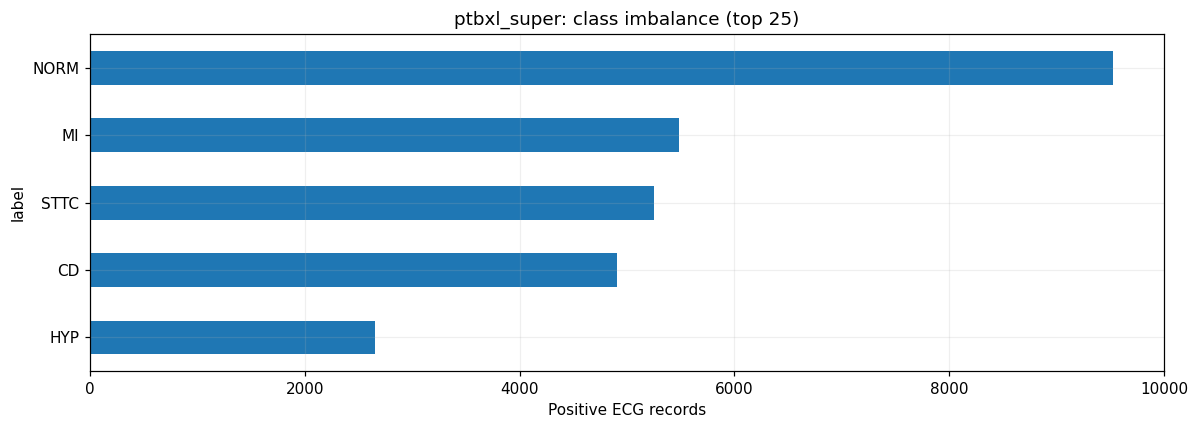

ptbxl_sub | target shape: (21837, 23) | classes: ['AMI', 'CLBBB', 'CRBBB', 'ILBBB', 'IMI', 'IRBBB', 'ISCA', 'ISCI', 'ISC_', 'IVCD', 'LAFB/LPFB', 'LAO/LAE', 'LMI', 'LVH', 'NORM', 'NST_', 'PMI', 'RAO/RAE', 'RVH', 'SEHYP', 'STTC', 'WPW', '_AVB']


,mapping_occurrences,positive_records,prevalence_percent,train_positive,train_negative,train_prevalence_percent,train_auc_defined,validation_positive,validation_negative,validation_prevalence_percent,validation_auc_defined,test_positive,test_negative,test_prevalence_percent,test_auc_defined
label,,,,,,,,,,,,,,,
NORM,9528,9528,43.632367,7607,9834,43.615618,True,957,1236,43.638851,True,964,1239,43.758511,True
IMI,3281,3281,15.024958,2623,14818,15.039275,True,330,1863,15.047880,True,328,1875,14.888788,True
AMI,3387,3086,14.131978,2471,14970,14.167766,True,307,1886,13.999088,True,308,1895,13.980935,True
STTC,2329,2244,10.276137,1795,15646,10.291841,True,226,1967,10.305518,True,223,1980,10.122560,True
LVH,2137,2137,9.786143,1710,15731,9.804484,True,213,1980,9.712722,True,214,1989,9.714026,True
LAFB/LPFB,1803,1800,8.242891,1439,16002,8.250674,True,181,2012,8.253534,True,180,2023,8.170676,True
ISC_,1275,1275,5.838714,1020,16421,5.848289,True,127,2066,5.791154,True,128,2075,5.810259,True
IRBBB,1118,1118,5.119751,894,16547,5.125853,True,112,2081,5.107159,True,112,2091,5.083976,True
ISCA,1016,944,4.322938,758,16683,4.346081,True,92,2101,4.195166,True,94,2109,4.266909,True


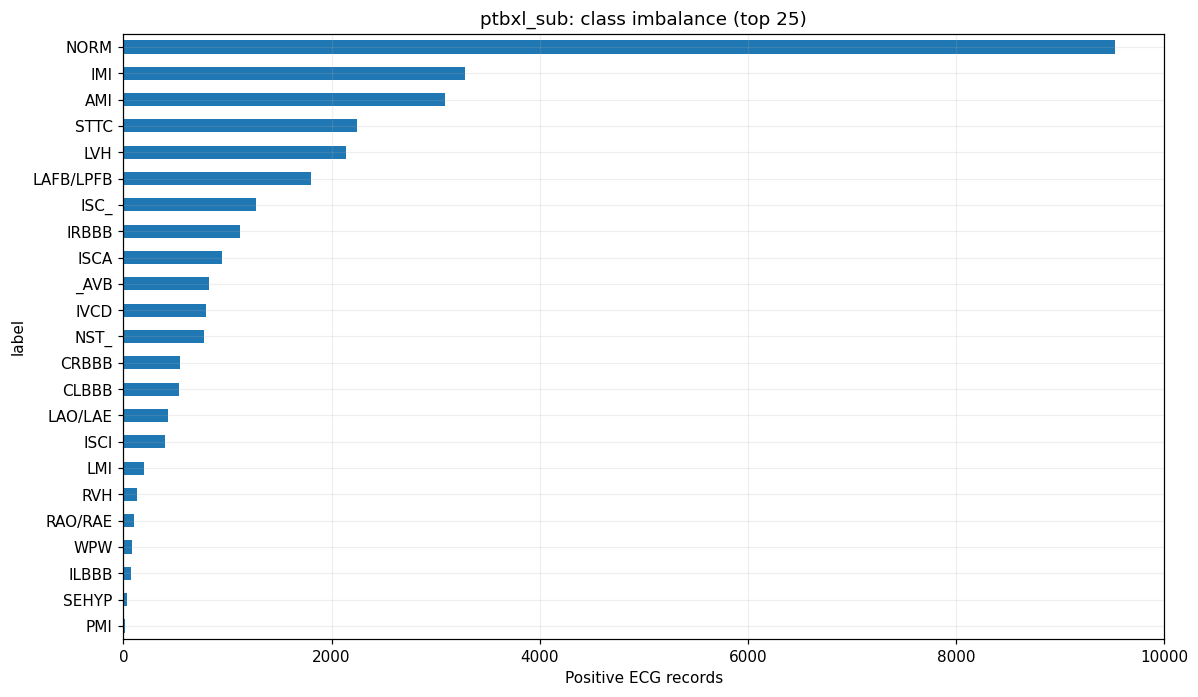

ptbxl_all | target shape: (21837, 71) | classes: ['1AVB', '2AVB', '3AVB', 'ABQRS', 'AFIB', 'AFLT', 'ALMI', 'AMI', 'ANEUR', 'ASMI', 'BIGU', 'CLBBB', 'CRBBB', 'DIG', 'EL', 'HVOLT', 'ILBBB', 'ILMI', 'IMI', 'INJAL', 'INJAS', 'INJIL', 'INJIN', 'INJLA', 'INVT', 'IPLMI', 'IPMI', 'IRBBB', 'ISCAL', 'ISCAN', 'ISCAS', 'ISCIL', 'ISCIN', 'ISCLA', 'ISC_', 'IVCD', 'LAFB', 'LAO/LAE', 'LMI', 'LNGQT', 'LOWT', 'LPFB', 'LPR', 'LVH', 'LVOLT', 'NDT', 'NORM', 'NST_', 'NT_', 'PAC', 'PACE', 'PMI', 'PRC(S)', 'PSVT', 'PVC', 'QWAVE', 'RAO/RAE', 'RVH', 'SARRH', 'SBRAD', 'SEHYP', 'SR', 'STACH', 'STD_', 'STE_', 'SVARR', 'SVTAC', 'TAB_', 'TRIGU', 'VCLVH', 'WPW']


,mapping_occurrences,positive_records,prevalence_percent,train_positive,train_negative,train_prevalence_percent,train_auc_defined,validation_positive,validation_negative,validation_prevalence_percent,validation_auc_defined,test_positive,test_negative,test_prevalence_percent,test_auc_defined,description
label,,,,,,,,,,,,,,,,
SR,16782,16782,76.851216,13426,4015,76.979531,True,1678,515,76.516188,True,1678,525,76.168861,True,sinus rhythm
NORM,9528,9528,43.632367,7607,9834,43.615618,True,957,1236,43.638851,True,964,1239,43.758511,True,normal ECG
ABQRS,3327,3327,15.235609,2683,14758,15.383292,True,322,1871,14.683083,True,322,1881,14.616432,True,abnormal QRS
IMI,2685,2685,12.295645,2148,15293,12.315808,True,269,1924,12.266302,True,268,1935,12.165229,True,inferior myocardial infarction
ASMI,2363,2363,10.821083,1890,15551,10.836535,True,237,1956,10.807114,True,236,1967,10.712665,True,anteroseptal myocardial infarction
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
INJLA,17,17,0.077850,13,17428,0.074537,True,2,2191,0.091199,True,2,2201,0.090785,True,subendocardial injury in lateral leads
3AVB,16,16,0.073270,12,17429,0.068803,True,2,2191,0.091199,True,2,2201,0.090785,True,third degree AV block
INJIL,15,15,0.068691,11,17430,0.063070,True,2,2191,0.091199,True,2,2201,0.090785,True,subendocardial injury in inferolateral leads


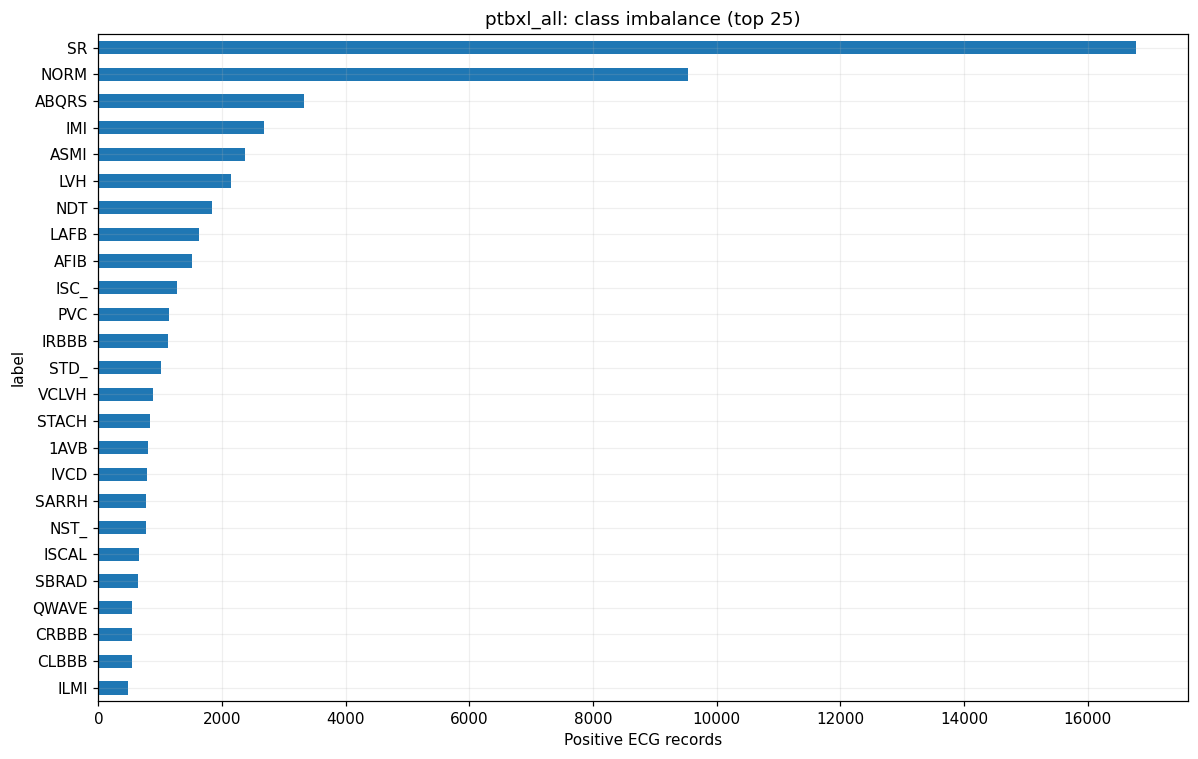

,task,expected_classes,observed_classes,retained_classes,matches_expected,records,no_label_records,single_label_records,multi_label_records,mean_labels_per_record,label_density
0,ptbxl_super,5,5,5,True,21837,407,16272,5158,1.274259,0.254852
1,ptbxl_sub,23,23,23,True,21837,407,15239,6191,1.389019,0.060392
2,ptbxl_all,71,71,71,True,21837,0,705,21132,2.798873,0.039421


,ecg_id,scp_codes,positive_labels,multi_hot
0,1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",[NORM],"[0, 0, 0, 1, 0]"
1,2,"{'NORM': 80.0, 'SBRAD': 0.0}",[NORM],"[0, 0, 0, 1, 0]"
2,3,"{'NORM': 100.0, 'SR': 0.0}",[NORM],"[0, 0, 0, 1, 0]"
3,4,"{'NORM': 100.0, 'SR': 0.0}",[NORM],"[0, 0, 0, 1, 0]"
4,5,"{'NORM': 100.0, 'SR': 0.0}",[NORM],"[0, 0, 0, 1, 0]"
5,6,"{'NORM': 100.0, 'SR': 0.0}",[NORM],"[0, 0, 0, 1, 0]"
6,7,"{'NORM': 100.0, 'SR': 0.0}",[NORM],"[0, 0, 0, 1, 0]"
7,8,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",[MI],"[0, 0, 1, 0, 0]"


In [7]:
task_data, task_summaries = {}, []
for task in eda.TASKS:
    classes, targets, counts, summary = eda.make_task_targets(df, statements, task, MIN_LABEL_COUNT)
    task_data[task] = (classes, targets, counts)
    task_summaries.append(summary)
    counts.to_csv(OUTPUT / f'{task}_label_counts.csv')
    np.savez_compressed(OUTPUT / f'{task}_targets.npz', targets=targets, classes=np.asarray(classes), ecg_id=df.ecg_id.to_numpy())
    print(task, '| target shape:', targets.shape, '| classes:', classes)
    display(counts.sort_values('positive_records', ascending=False))
    if len(classes):
        ordered = counts.nlargest(TOP_LABELS, 'positive_records').sort_values('positive_records')
        fig, ax = plt.subplots(figsize=(11, max(4, len(ordered) * .28)))
        ordered.positive_records.plot.barh(ax=ax)
        ax.set(xlabel='Positive ECG records', title=f'{task}: class imbalance (top {TOP_LABELS})')
        save_figure(fig, f'{task}_label_frequency.png')
summaries = pd.DataFrame(task_summaries)
display(summaries)
summaries.to_csv(OUTPUT / 'task_summary.csv', index=False)
if not summaries.matches_expected.all():
    print('VOCABULARY ALERT: retained labels differ from 5/23/71; inspect dataset version and min-count before training.')

classes, targets, counts = task_data[TASK_TO_INSPECT]
display(pd.DataFrame({'ecg_id': df.ecg_id.head(8), 'scp_codes': df.scp_codes.head(8),
    'positive_labels': [[classes[j] for j in np.flatnonzero(targets[i])] for i in range(min(8, len(df)))],
    'multi_hot': [targets[i].tolist() for i in range(min(8, len(df)))]}))

## 8. Một ECG mang bao nhiêu nhãn?

**Label cardinality** là số bit 1 mỗi bản ghi; **label density** là tỷ lệ bit 1 trong toàn bộ ma trận nhãn. Tỷ lệ bản ghi có từ hai nhãn trở lên cho thấy mức độ đa nhãn của từng tác vụ. Không dùng argmax để biến bài toán thành một lớp duy nhất.

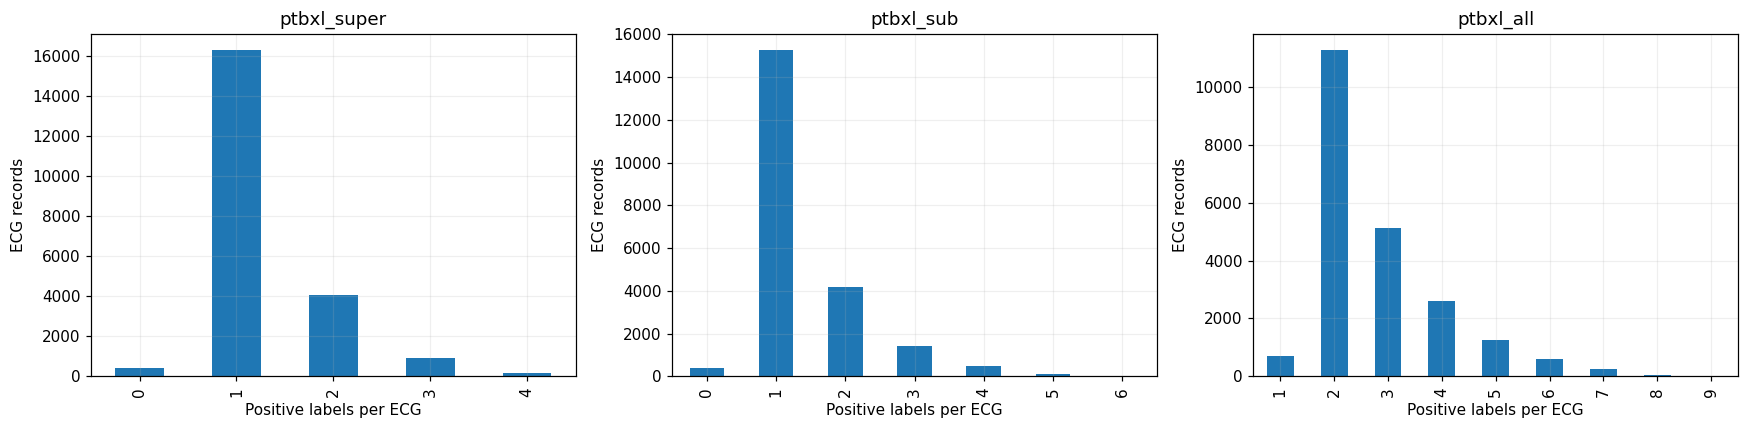

,task,no_label_records,single_label_records,multi_label_records,mean_labels_per_record,label_density
0,ptbxl_super,407,16272,5158,1.274259,0.254852
1,ptbxl_sub,407,15239,6191,1.389019,0.060392
2,ptbxl_all,0,705,21132,2.798873,0.039421


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
cardinality_rows = []
for ax, (task, (classes, targets, counts)) in zip(axes, task_data.items()):
    cardinality = targets.sum(1).astype(int)
    distribution = pd.Series(cardinality).value_counts().sort_index()
    distribution.plot.bar(ax=ax)
    ax.set(title=task, xlabel='Positive labels per ECG', ylabel='ECG records')
    cardinality_rows.extend(dict(task=task, labels_per_record=int(k), records=int(v)) for k, v in distribution.items())
save_figure(fig, 'label_cardinality.png')
pd.DataFrame(cardinality_rows).to_csv(OUTPUT / 'label_cardinality.csv', index=False)
display(summaries[['task', 'no_label_records', 'single_label_records', 'multi_label_records', 'mean_labels_per_record', 'label_density']])

## 9. Đồng xuất hiện nhãn và phân bố giữa các split

Ma trận count cho biết hai nhãn cùng xuất hiện trong bao nhiêu ECG. Jaccard = giao/hợp, giúp nhìn quan hệ mà bớt bị chi phối bởi nhãn phổ biến. Đây là quan hệ thống kê, không phải quan hệ nhân quả hay chẩn đoán.

Bảng `*_auc_defined` đánh dấu lớp có đủ mẫu dương và âm ở mỗi split để tính AUROC. Một lớp hiếm có thể vắng ở validation/test; cần đọc số lớp hợp lệ khi so sánh macro-AUROC.

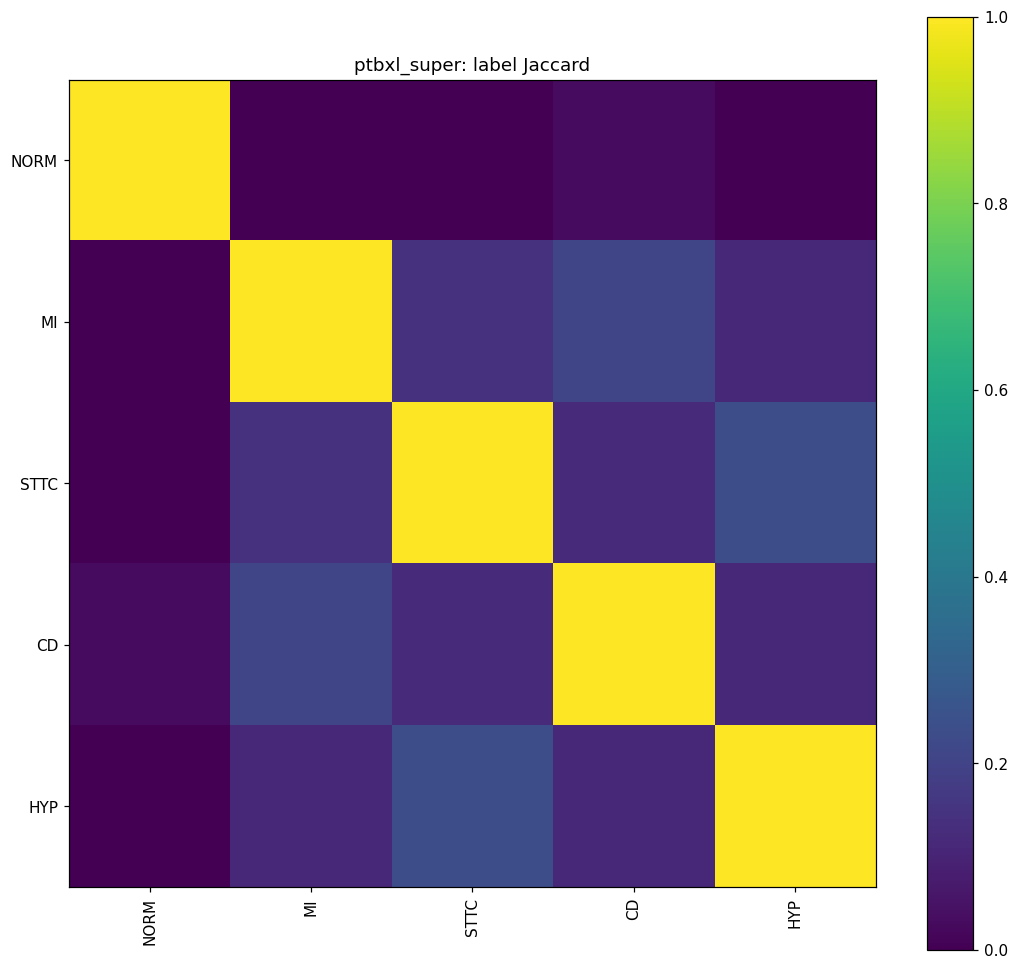

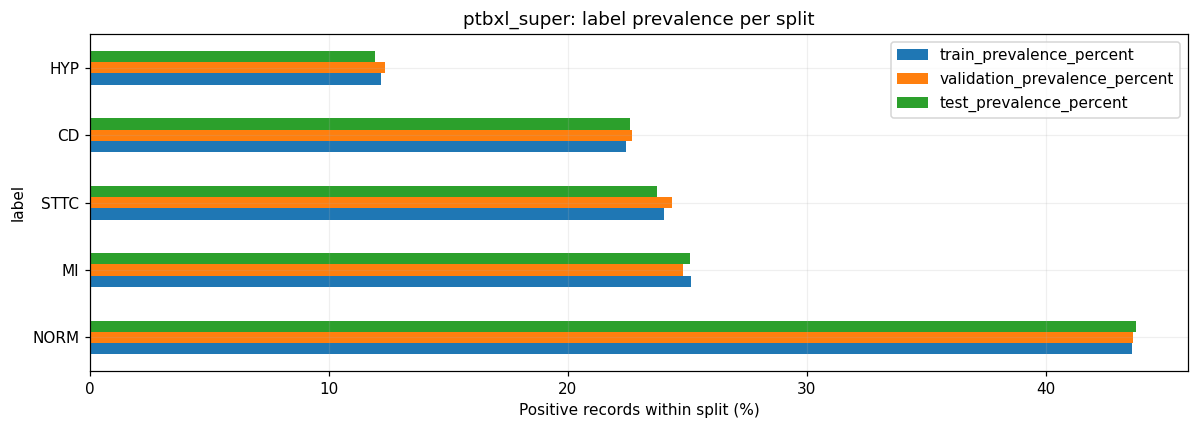

ptbxl_super | labels with undefined AUROC in at least one split: 0


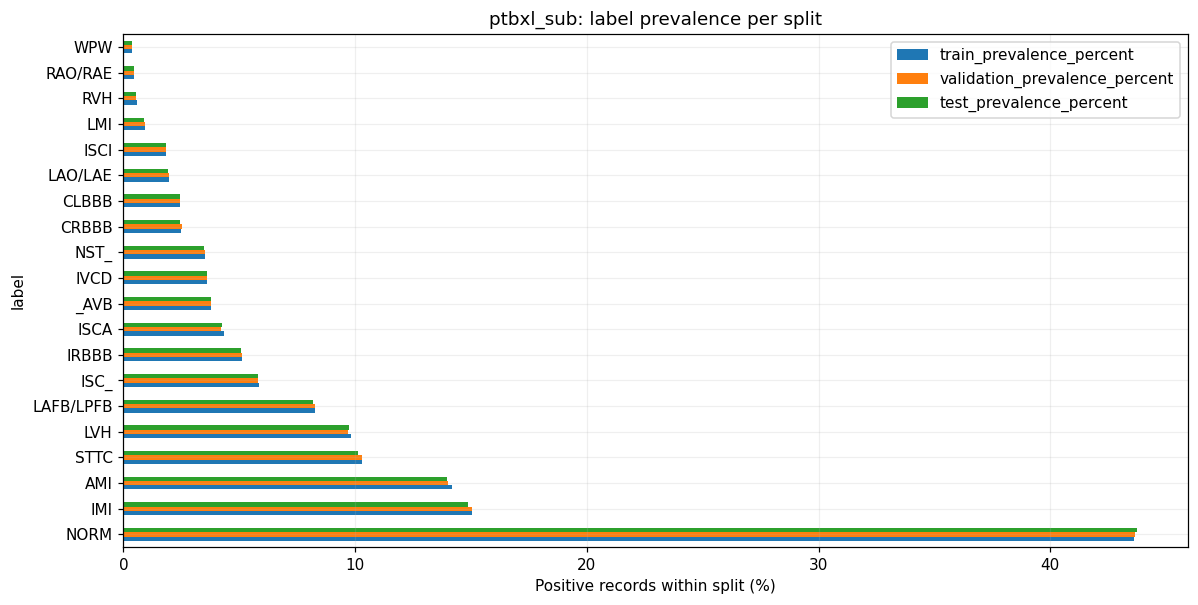

ptbxl_sub | labels with undefined AUROC in at least one split: 0


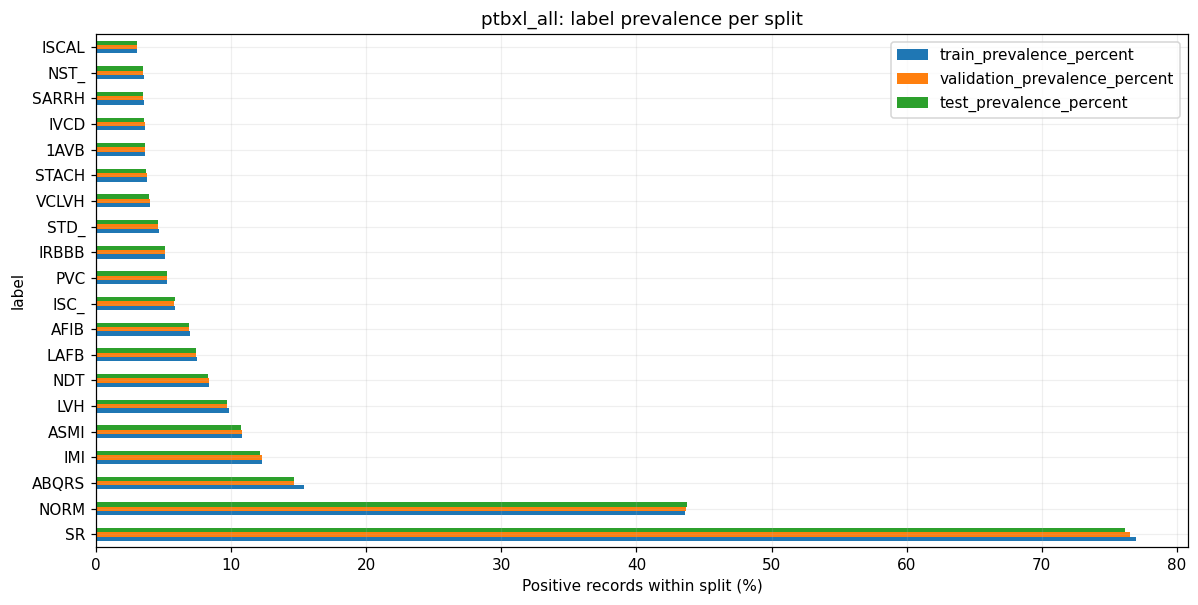

ptbxl_all | labels with undefined AUROC in at least one split: 0


In [9]:
classes, targets, counts = task_data[TASK_TO_INSPECT]
if classes:
    binary = targets.astype(np.int64)  # uint8 matmul would overflow above 255 co-occurrences
    cooccurrence = binary.T @ binary
    totals = binary.sum(0)
    union = totals[:, None] + totals[None, :] - cooccurrence
    jaccard = np.divide(cooccurrence, union, out=np.zeros_like(cooccurrence, dtype=float), where=union > 0)
    pd.DataFrame(cooccurrence, index=classes, columns=classes).to_csv(OUTPUT / f'{TASK_TO_INSPECT}_cooccurrence.csv')
    pd.DataFrame(jaccard, index=classes, columns=classes).to_csv(OUTPUT / f'{TASK_TO_INSPECT}_jaccard.csv')
    selected = np.argsort(-totals)[:min(20, len(classes))]
    fig, ax = plt.subplots(figsize=(10, 9))
    view = ax.imshow(jaccard[np.ix_(selected, selected)], vmin=0, vmax=1, cmap='viridis')
    names = np.asarray(classes)[selected]
    ax.set_xticks(range(len(selected)), names, rotation=90)
    ax.set_yticks(range(len(selected)), names)
    ax.set_title(f'{TASK_TO_INSPECT}: label Jaccard')
    ax.grid(False)
    fig.colorbar(view, ax=ax)
    save_figure(fig, 'label_jaccard.png')
for task, (classes, targets, counts) in task_data.items():
    selected_counts = counts.nlargest(min(20, len(classes)), 'positive_records')
    if not len(selected_counts):
        continue
    fig, ax = plt.subplots(figsize=(11, max(4, len(selected_counts) * .28)))
    selected_counts[['train_prevalence_percent', 'validation_prevalence_percent', 'test_prevalence_percent']].plot.barh(ax=ax)
    ax.set(xlabel='Positive records within split (%)', title=f'{task}: label prevalence per split')
    save_figure(fig, f'{task}_split_prevalence.png')
    invalid = counts.loc[~counts[['train_auc_defined', 'validation_auc_defined', 'test_auc_defined']].all(axis=1)]
    print(task, '| labels with undefined AUROC in at least one split:', len(invalid))
    if len(invalid):
        display(invalid)

## 10. Đọc waveform và khảo sát shape, tần số, biên độ, dữ liệu không hữu hạn

Phần này đọc mẫu waveform có seed, phân bổ để phủ các split; **không phải mẫu tỷ lệ theo kích thước split**. Đơn vị từ header được giữ nguyên. Thống kê gồm số mẫu, số lead, thời lượng, mean/std/RMS/peak-to-peak, percentile 99 của biên độ tuyệt đối, giá trị không hữu hạn và lead hằng.

`fraction_abs_gt_3_5_mv` chỉ cho biết tỷ lệ mẫu sẽ vượt thang ±3.5 mV của notebook ảnh đã tạo, không phải tiêu chí xác định bệnh hay chất lượng tín hiệu.

Scanning 256 / 21837 records; signal version: hr


,sample_records
split,
test,86
train,85
validation,85


  0%|          | 0/256 [00:00<?, ?it/s]

,ecg_id,error


,ecg_id,split,fs,samples,channels,duration_seconds,lead_order,units,nonfinite_samples
0,15744,test,500.0,5000,12,10.0,i|ii|iii|avr|avl|avf|v1|v2|v3|v4|v5|v6,mV|mV|mV|mV|mV|mV|mV|mV|mV|mV|mV|mV,0
1,18208,train,500.0,5000,12,10.0,i|ii|iii|avr|avl|avf|v1|v2|v3|v4|v5|v6,mV|mV|mV|mV|mV|mV|mV|mV|mV|mV|mV|mV,0
2,3083,validation,500.0,5000,12,10.0,i|ii|iii|avr|avl|avf|v1|v2|v3|v4|v5|v6,mV|mV|mV|mV|mV|mV|mV|mV|mV|mV|mV|mV,0
3,15207,test,500.0,5000,12,10.0,i|ii|iii|avr|avl|avf|v1|v2|v3|v4|v5|v6,mV|mV|mV|mV|mV|mV|mV|mV|mV|mV|mV|mV,0
4,433,train,500.0,5000,12,10.0,i|ii|iii|avr|avl|avf|v1|v2|v3|v4|v5|v6,mV|mV|mV|mV|mV|mV|mV|mV|mV|mV|mV|mV,0


,,,,sample_records
fs,samples,channels,duration_seconds,
500.0,5000,12,10.0,256


,,mean,std,peak_to_peak,rms,abs_p99
lead,unit,,,,,
avf,mV,-0.000398,0.107544,0.8915,0.107637,0.435015
avl,mV,-0.000873,0.104851,0.9150,0.104953,0.458020
avr,mV,0.000843,0.122675,1.0035,0.123577,0.595020
i,mV,-0.001330,0.128425,1.0820,0.128661,0.615525
ii,mV,-0.001047,0.135112,1.0910,0.135531,0.567500
iii,mV,0.000420,0.115704,1.0005,0.115791,0.483530
v1,mV,-0.000152,0.154584,1.2590,0.155107,0.781510
v2,mV,-0.001020,0.239716,2.0680,0.239716,1.104530
v3,mV,-0.001379,0.242845,2.0665,0.242891,1.029065


Sample records with non-finite samples: 0
Sample record-lead pairs that are constant: 0


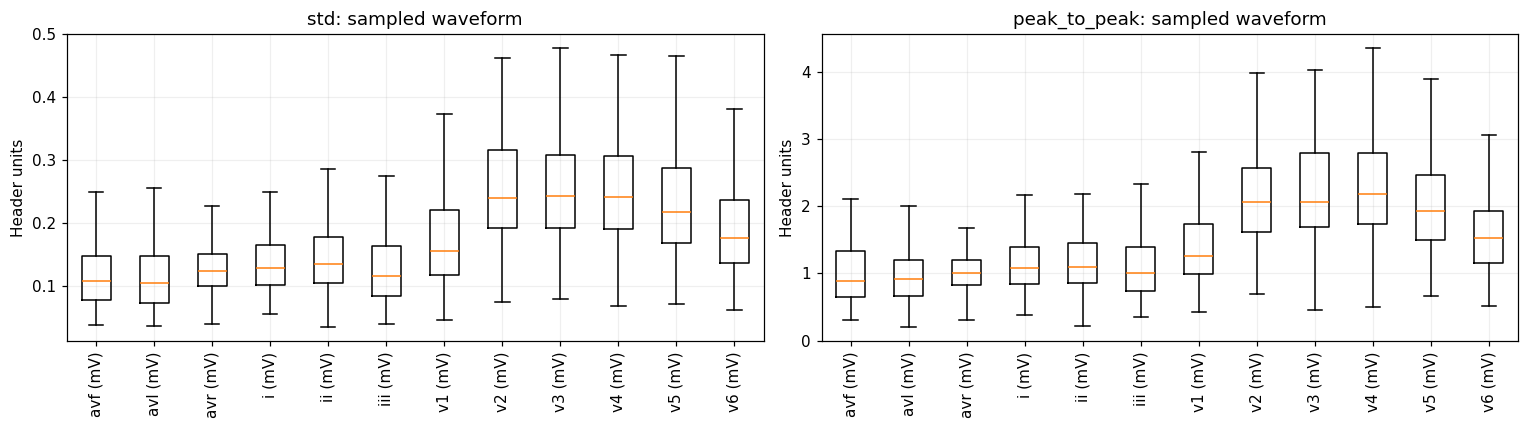

In [10]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
sample = eda.stratified_sample(df, WAVEFORM_SAMPLE_SIZE, SEED)
sample[['ecg_id', 'patient_id', 'split', 'strat_fold']].to_csv(OUTPUT / 'waveform_sample_records.csv', index=False)
print('Scanning', len(sample), '/', len(df), 'records; signal version:', SIGNAL_VERSION)
display(sample['split'].value_counts().to_frame('sample_records'))

def scan_one(row):
    try:
        record, leads = eda.waveform_statistics(root, row, SIGNAL_VERSION)
        return record, leads, None
    except Exception as error:
        return None, [], dict(ecg_id=int(row.ecg_id), error=str(error))

record_rows, lead_rows, error_rows = [], [], []
with ThreadPoolExecutor(max_workers=SCAN_WORKERS) as pool:
    for record, leads, error in tqdm(pool.map(scan_one, [row for _, row in sample.iterrows()]), total=len(sample)):
        if record is not None:
            record_rows.append(record)
            lead_rows.extend(leads)
        if error is not None:
            error_rows.append(error)
record_stats = pd.DataFrame(record_rows)
lead_stats = pd.DataFrame(lead_rows)
errors = pd.DataFrame(error_rows, columns=['ecg_id', 'error'])
record_stats.to_csv(OUTPUT / 'waveform_record_stats.csv', index=False)
lead_stats.to_csv(OUTPUT / 'waveform_lead_stats.csv', index=False)
errors.to_csv(OUTPUT / 'waveform_read_errors.csv', index=False)
display(errors)
assert len(record_stats), 'Không đọc được waveform; kiểm tra filename_hr/lr và đường dẫn records.'
display(record_stats.head())
display(record_stats.groupby(['fs', 'samples', 'channels', 'duration_seconds']).size().to_frame('sample_records'))
display(lead_stats.groupby(['lead', 'unit'])[['mean', 'std', 'peak_to_peak', 'rms', 'abs_p99']].median())
print('Sample records with non-finite samples:', int(record_stats.nonfinite_samples.gt(0).sum()))
print('Sample record-lead pairs that are constant:', int(lead_stats.constant_lead.sum()))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, ax in zip(['std', 'peak_to_peak'], axes):
    usable = lead_stats.replace([np.inf, -np.inf], np.nan).dropna(subset=[name])
    if len(usable):
        groups = [g[name].to_numpy() for _, g in usable.groupby(['lead', 'unit'], sort=True)]
        labels = [f'{lead} ({unit})' for lead, unit in usable.groupby(['lead', 'unit'], sort=True).groups]
        ax.boxplot(groups, showfliers=False)
        ax.set_xticks(range(1, len(labels) + 1), labels, rotation=90)
    ax.set(title=f'{name}: sampled waveform', ylabel='Header units')
save_figure(fig, 'waveform_amplitude_stats.png')

## 11. Vẽ đủ 12 chuyển đạo và xem vector nhãn của ECG

Đây là biểu đồ khảo sát tín hiệu, không phải đầu vào dạng ảnh cho pipeline waveform. Mô hình waveform vẫn nhận trực tiếp tensor số. Nhãn trong tiêu đề được lấy từ metadata để đối chiếu, không phải dự đoán mô hình.

ecg_id: 15744 | signal shape [time, lead]: (5000, 12) | model full-record shape [lead, time]: (12, 5000)
classes: ['CD', 'HYP', 'MI', 'NORM', 'STTC'] | multi-hot: [0, 0, 0, 0, 1] | positive labels: ['STTC']


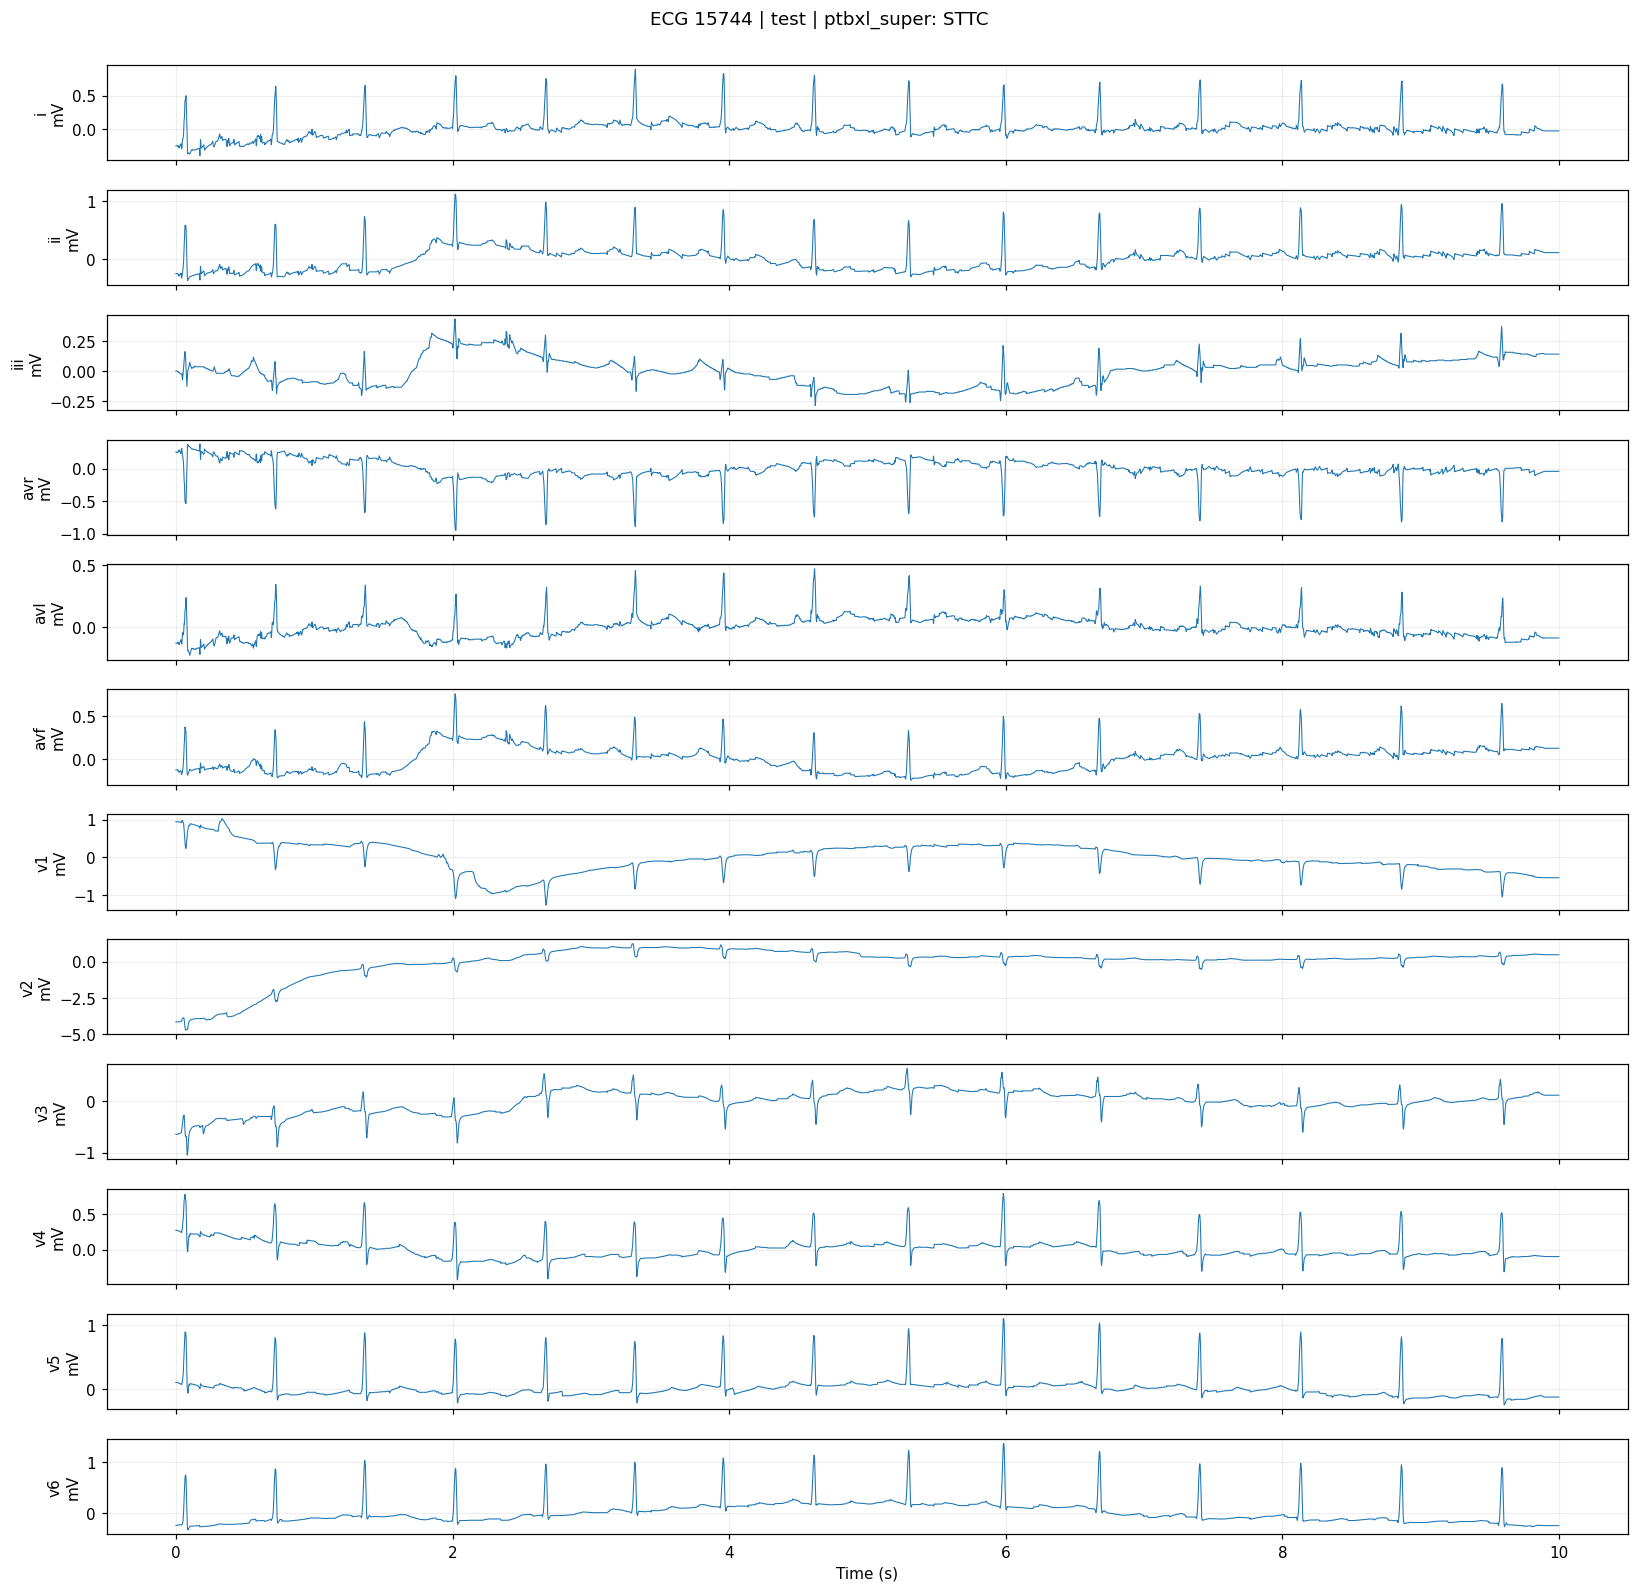

ecg_id: 18208 | signal shape [time, lead]: (5000, 12) | model full-record shape [lead, time]: (12, 5000)
classes: ['CD', 'HYP', 'MI', 'NORM', 'STTC'] | multi-hot: [0, 0, 0, 1, 0] | positive labels: ['NORM']


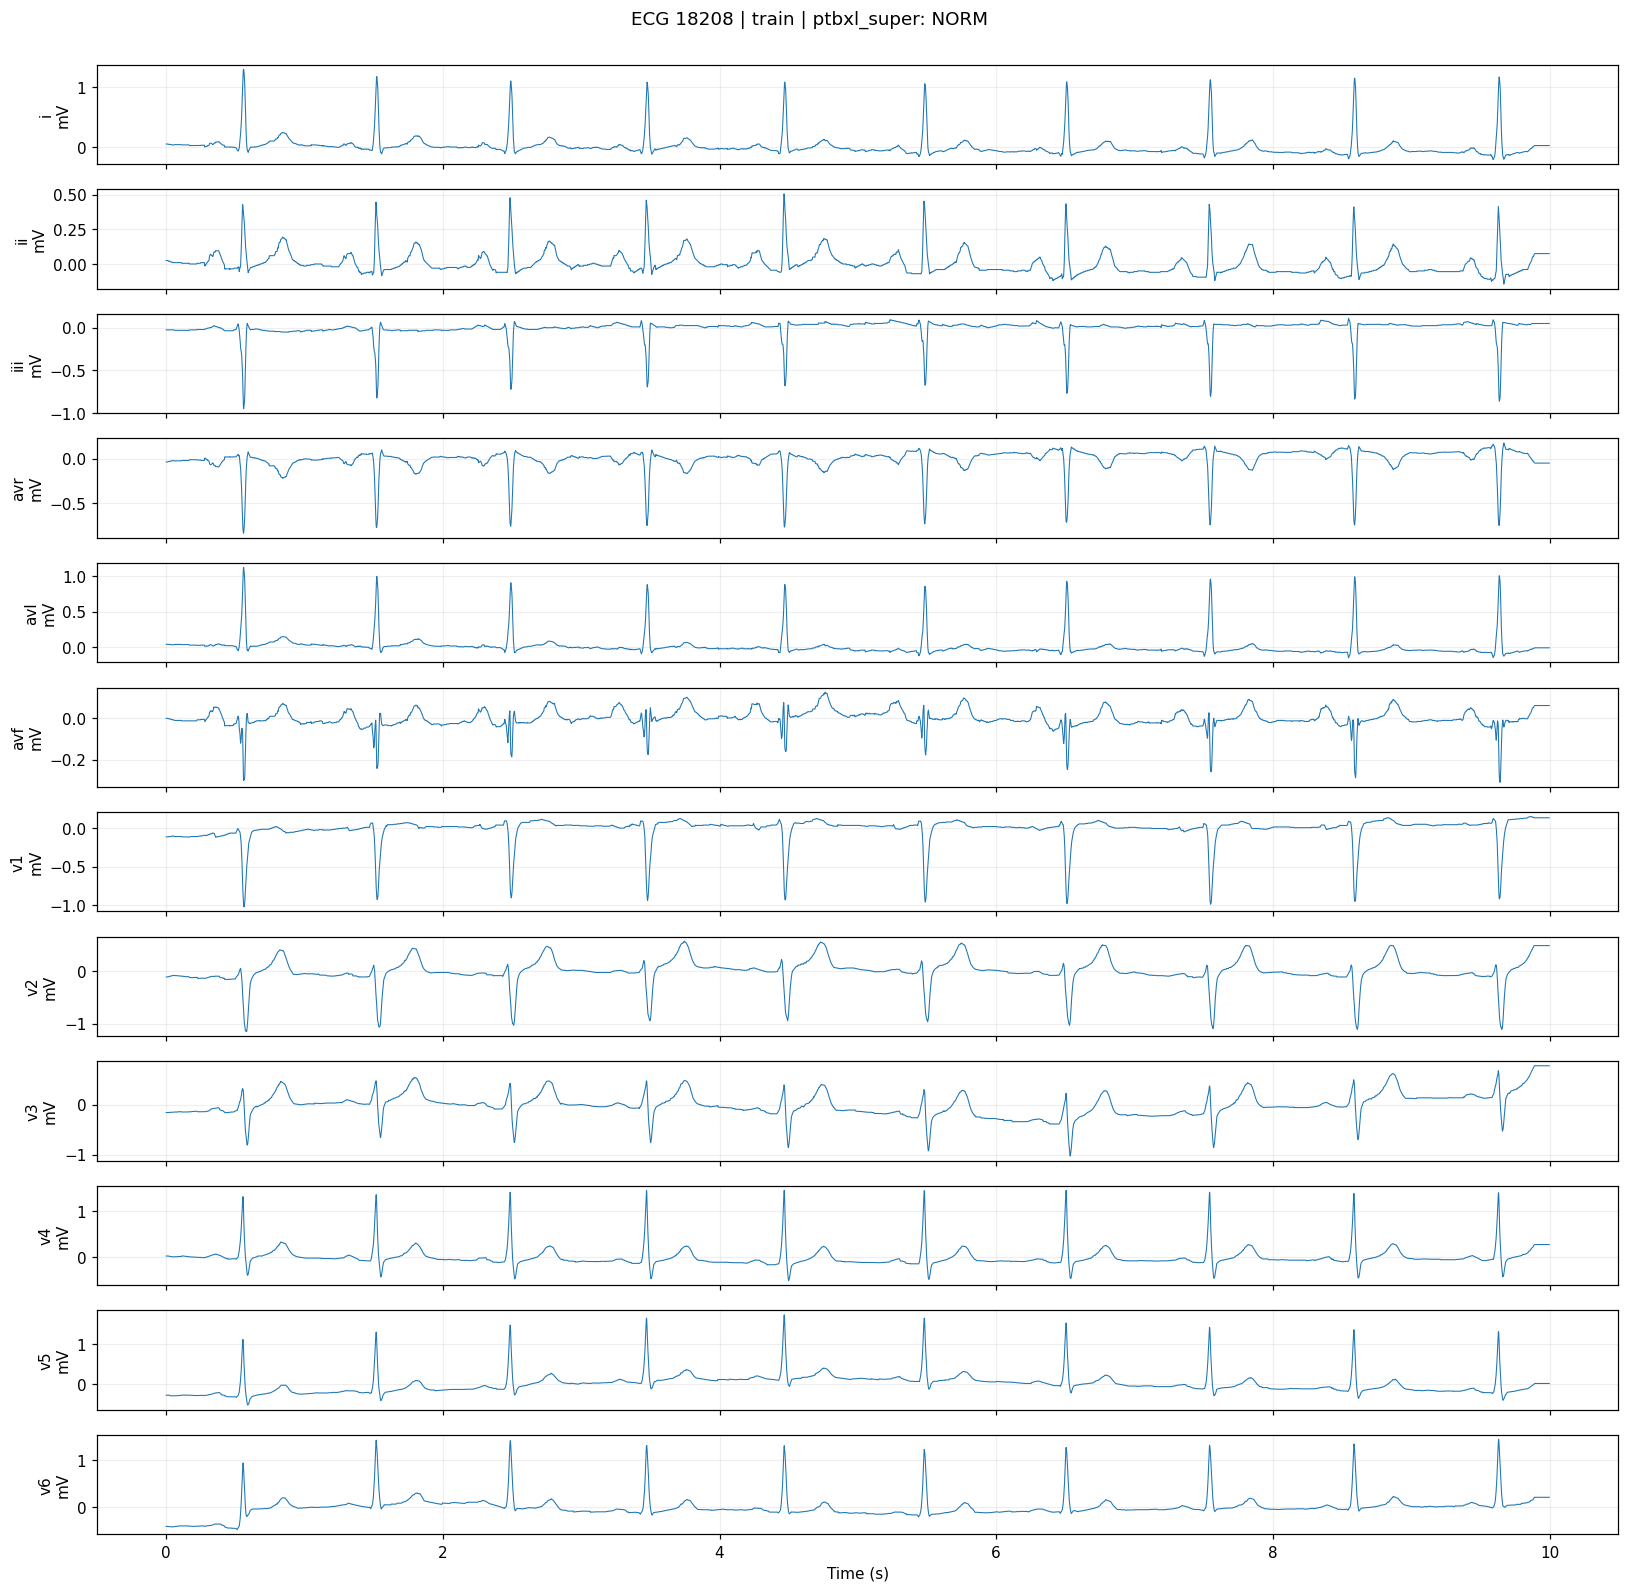

ecg_id: 3083 | signal shape [time, lead]: (5000, 12) | model full-record shape [lead, time]: (12, 5000)
classes: ['CD', 'HYP', 'MI', 'NORM', 'STTC'] | multi-hot: [0, 0, 0, 1, 0] | positive labels: ['NORM']


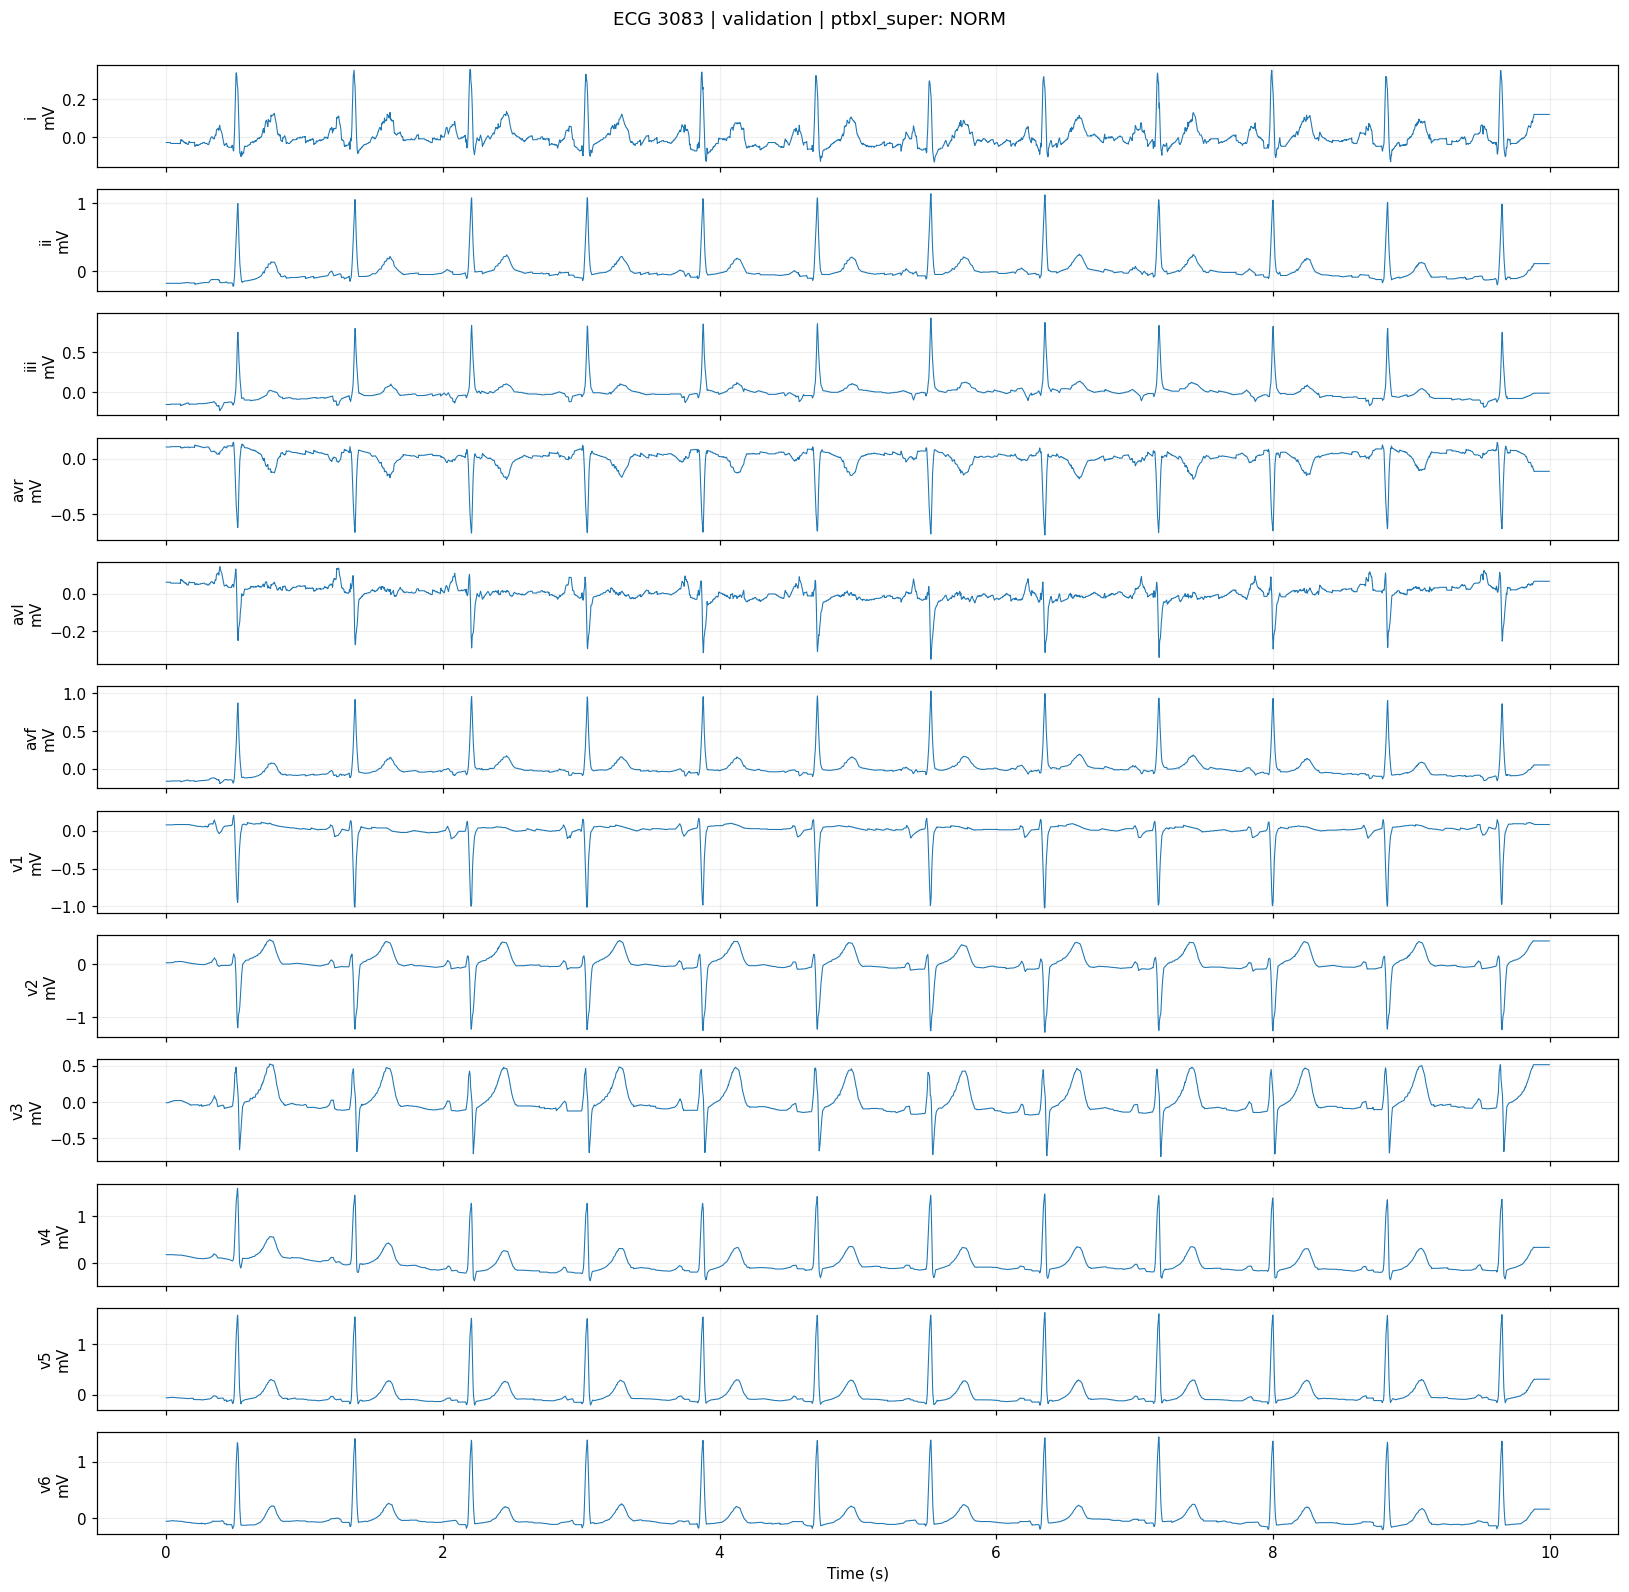

In [11]:
example_ids = EXAMPLE_ECG_IDS or record_stats.ecg_id.head(3).astype(int).tolist()
classes, targets, _ = task_data[TASK_TO_INSPECT]
for ecg_id in example_ids:
    matches = np.flatnonzero(df.ecg_id.eq(ecg_id).to_numpy())
    assert len(matches) == 1, f'ecg_id={ecg_id} missing or duplicated'
    position = int(matches[0])
    row = df.iloc[position]
    signal, header = eda.read_waveform(root, row, SIGNAL_VERSION)
    positive = [classes[i] for i in np.flatnonzero(targets[position])]
    print('ecg_id:', ecg_id, '| signal shape [time, lead]:', signal.shape,
          '| model full-record shape [lead, time]:', signal.T.shape)
    print('classes:', classes, '| multi-hot:', targets[position].tolist(), '| positive labels:', positive)
    times = np.arange(len(signal)) / header['fs']
    fig, axes = plt.subplots(signal.shape[1], 1, figsize=(15, signal.shape[1] * 1.2), sharex=True, squeeze=False)
    for i, ax in enumerate(axes[:, 0]):
        ax.plot(times, signal[:, i], linewidth=.7)
        ax.set_ylabel(f"{header['sig_name'][i]}\n{header['units'][i]}")
    axes[-1, 0].set_xlabel('Time (s)')
    fig.suptitle(f'ECG {ecg_id} | {row["split"]} | {TASK_TO_INSPECT}: {", ".join(positive) or "no retained labels"}', y=1.002)
    save_figure(fig, f'waveform_ecg_{ecg_id}.png')

## 12. Tương quan giữa các lead và phổ công suất

Ví dụ trên một bản ghi. Welch PSD cho thấy năng lượng theo tần số; đỉnh 50/60 Hz có thể dùng để khảo sát nhiễu nhưng không tự kết luận chất lượng hoặc bệnh. Không sửa/lọc waveform trong notebook này. Các lead hằng hoặc dữ liệu thiếu có thể khiến tương quan không xác định.

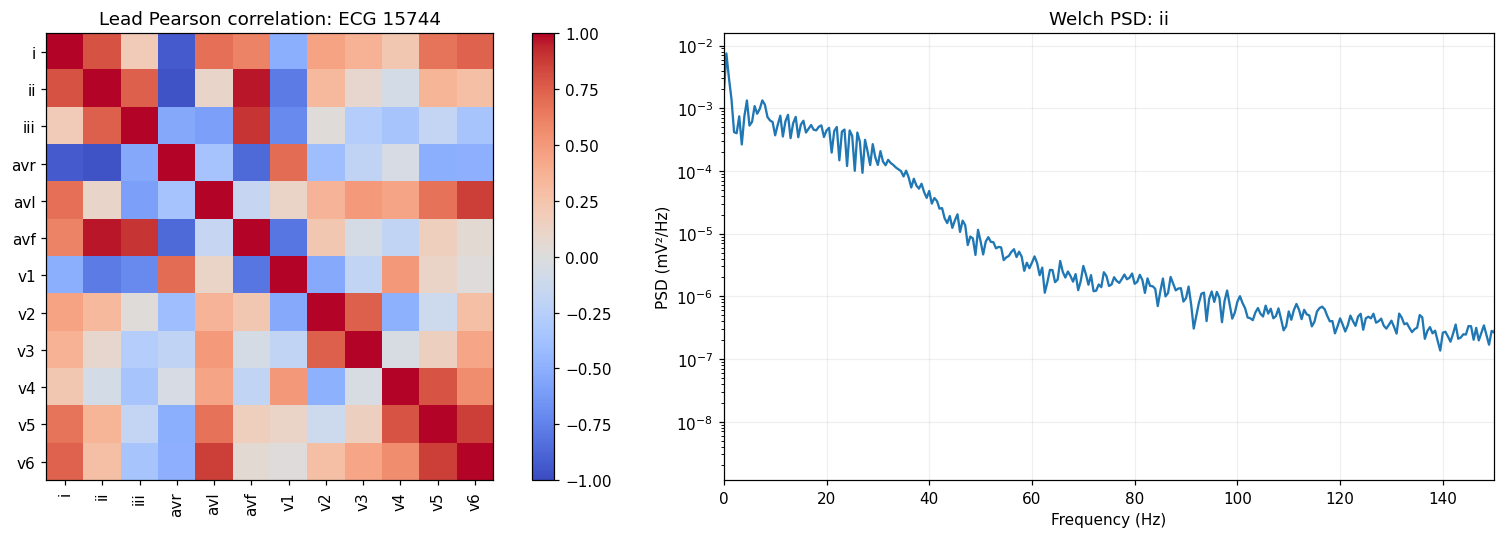

In [12]:
from scipy.signal import welch
row = df.loc[df.ecg_id.eq(example_ids[0])].iloc[0]
signal, header = eda.read_waveform(root, row, SIGNAL_VERSION)
lead_names = header['sig_name']
correlation = pd.DataFrame(signal, columns=lead_names).corr()
correlation.to_csv(OUTPUT / f'lead_correlation_ecg_{int(row.ecg_id)}.csv')
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
view = axes[0].imshow(correlation, vmin=-1, vmax=1, cmap='coolwarm')
axes[0].set_xticks(range(len(lead_names)), lead_names, rotation=90)
axes[0].set_yticks(range(len(lead_names)), lead_names)
axes[0].set_title(f'Lead Pearson correlation: ECG {int(row.ecg_id)}')
axes[0].grid(False)
fig.colorbar(view, ax=axes[0])
lead_index = lead_names.index('ii') if 'ii' in lead_names else 0
values = signal[:, lead_index]
if np.isfinite(values).all():
    frequency, psd = welch(values, fs=header['fs'], nperseg=min(len(values), int(2 * header['fs'])))
    axes[1].semilogy(frequency, np.maximum(psd, np.finfo(float).tiny))
    axes[1].set(xlim=(0, min(150, header['fs'] / 2)), xlabel='Frequency (Hz)',
                ylabel=f"PSD ({header['units'][lead_index]}²/Hz)", title=f'Welch PSD: {lead_names[lead_index]}')
    pd.DataFrame({'frequency_hz': frequency, 'psd': psd}).to_csv(OUTPUT / 'example_welch_psd.csv', index=False)
else:
    axes[1].text(.1, .5, 'Non-finite values: PSD skipped')
save_figure(fig, 'lead_correlation_and_psd.png')

## 13. Tổng hợp và tải báo cáo

Báo cáo gồm CSV, ma trận target/classes, biểu đồ PNG và JSON cấu hình. Không chứa toàn bộ waveform hoặc ảnh biến đổi để train. Các thống kê nhãn dùng toàn bộ metadata; waveform dùng đúng mẫu đã lưu trong `waveform_sample_records.csv`. Khi huấn luyện thực tế, tham số chuẩn hóa hoặc ngưỡng dự đoán cần được xác định từ train/validation, không fit trên test.

In [13]:
report = dict(records=len(df), patients=int(df.patient_id.nunique()),
              duplicate_ecg_ids=int(df.ecg_id.duplicated().sum()),
              invalid_fold_records=int(df.split.eq('invalid_fold').sum()),
              patient_overlap_pairs=int(overlaps.overlapping_patients.gt(0).sum()),
              waveform_scanned=len(record_stats), waveform_errors=len(errors),
              waveform_signal_version=SIGNAL_VERSION, waveform_sample_size=WAVEFORM_SAMPLE_SIZE,
              seed=SEED, min_label_count=MIN_LABEL_COUNT, tasks=task_summaries,
              helper_sha256=HELPER_SHA256, demographics=demographics)
(OUTPUT / 'eda_summary.json').write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame(task_summaries))
print('Outputs:', OUTPUT)
archive_path = OUTPUT.parent / 'ptbxl_waveform_eda_report.zip'
with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(OUTPUT.iterdir()):
        if path.is_file() and path.suffix in ['.csv', '.json', '.png', '.npz']:
            archive.write(path, path.name)
try:
    link_path = os.path.relpath(archive_path, Path.cwd())
except ValueError:  # Local Windows execution on different drives.
    link_path = str(archive_path)
display(FileLink(link_path))

,task,expected_classes,observed_classes,retained_classes,matches_expected,records,no_label_records,single_label_records,multi_label_records,mean_labels_per_record,label_density
0,ptbxl_super,5,5,5,True,21837,407,16272,5158,1.274259,0.254852
1,ptbxl_sub,23,23,23,True,21837,407,15239,6191,1.389019,0.060392
2,ptbxl_all,71,71,71,True,21837,0,705,21132,2.798873,0.039421


Outputs: /kaggle/working/ptbxl_waveform_eda


/kaggle/working/ptbxl_waveform_eda_report.zip